In [ ]:
# ==============================================================================
# CELL 1 — LOAD LIBRARIES
# Reproduction of Figure 1D (Gate et al.)
# ==============================================================================

suppressPackageStartupMessages({

  library(Matrix)
  library(Seurat)
  library(glmGamPoi)
  library(future)

})

options(future.globals.maxSize = 40 * 1024^3)

cat("Seurat version:", as.character(packageVersion("Seurat")), "\n")
cat("Matrix version:", as.character(packageVersion("Matrix")), "\n")
cat("glmGamPoi version:", as.character(packageVersion("glmGamPoi")), "\n")

Seurat version: 5.5.1 
Matrix version: 1.7.3 
glmGamPoi version: 1.22.0 


In [ ]:
# ==============================================================================
# CELL 2 — READ EXPORTED SPARSE MATRIX AND METADATA
# ==============================================================================

library(Matrix)

seurat_input_dir <- paste0(
  "/home/amithsiri/projects/",
  "Summer-Project-2026/",
  "Summer-Project-2026/",
  "Age_trajectory/",
  "results/",
  "figure1d_python/",
  "seurat_input"
)

matrix_path <- file.path(seurat_input_dir, "counts.mtx")
genes_path <- file.path(seurat_input_dir, "genes.tsv")
barcodes_path <- file.path(seurat_input_dir, "barcodes.tsv")
metadata_path <- file.path(seurat_input_dir, "metadata.csv")


# ------------------------------------------------------------------------------
# 1. Confirm every file exists
# ------------------------------------------------------------------------------

input_paths <- c(
  matrix = matrix_path,
  genes = genes_path,
  barcodes = barcodes_path,
  metadata = metadata_path
)

print(input_paths)

exists_check <- file.exists(input_paths)

print(exists_check)

if (!all(exists_check)) {
  stop(
    paste0(
      "One or more input files are missing:\n",
      paste(
        names(input_paths)[!exists_check],
        input_paths[!exists_check],
        sep = ": ",
        collapse = "\n"
      )
    )
  )
}


# ------------------------------------------------------------------------------
# 2. Read the sparse matrix and annotations
# ------------------------------------------------------------------------------

cat("\nReading Matrix Market count matrix...\n")

counts <- readMM(matrix_path)

cat("Matrix loaded.\n")


genes <- read.delim(
  genes_path,
  header = FALSE,
  stringsAsFactors = FALSE
)

barcodes <- read.delim(
  barcodes_path,
  header = FALSE,
  stringsAsFactors = FALSE
)

metadata <- read.csv(
  metadata_path,
  stringsAsFactors = FALSE,
  check.names = FALSE
)


# ------------------------------------------------------------------------------
# 3. Assign row and column names
# ------------------------------------------------------------------------------

gene_names <- genes[[1]]
cell_barcodes <- barcodes[[1]]

if (length(gene_names) != nrow(counts)) {
  stop(
    paste0(
      "Gene count mismatch: ",
      length(gene_names),
      " names for ",
      nrow(counts),
      " matrix rows."
    )
  )
}

if (length(cell_barcodes) != ncol(counts)) {
  stop(
    paste0(
      "Barcode count mismatch: ",
      length(cell_barcodes),
      " names for ",
      ncol(counts),
      " matrix columns."
    )
  )
}

rownames(counts) <- gene_names
colnames(counts) <- cell_barcodes


# ------------------------------------------------------------------------------
# 4. Align metadata to matrix columns
# ------------------------------------------------------------------------------

if (!"cell_barcode" %in% colnames(metadata)) {
  stop("metadata.csv does not contain a 'cell_barcode' column.")
}

if (anyDuplicated(metadata$cell_barcode) > 0) {
  stop("Duplicate cell barcodes were found in metadata.")
}

metadata <- metadata[
  match(
    colnames(counts),
    metadata$cell_barcode
  ),
  ,
  drop = FALSE
]

if (any(is.na(metadata$cell_barcode))) {
  stop(
    "Some matrix barcodes could not be matched to metadata."
  )
}

if (!identical(
  metadata$cell_barcode,
  colnames(counts)
)) {
  stop(
    "Metadata ordering does not match matrix columns."
  )
}

rownames(metadata) <- metadata$cell_barcode
# ------------------------------------------------------------------------------
# 5. Final validation
# ------------------------------------------------------------------------------

separator <- paste(rep("=", 80), collapse = "")

cat("\n", separator, "\n", sep = "")
cat("CELL 2 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")

cat(
  "Matrix dimensions: ",
  format(nrow(counts), big.mark = ","),
  " genes × ",
  format(ncol(counts), big.mark = ","),
  " cells\n",
  sep = ""
)

cat(
  "Metadata rows: ",
  format(nrow(metadata), big.mark = ","),
  "\n",
  sep = ""
)

cat(
  "GSM samples: ",
  length(unique(metadata$gsm)),
  "\n",
  sep = ""
)

cat(
  "Sparse matrix class: ",
  class(counts)[1],
  "\n",
  sep = ""
)

cat(
  "Cell order matches metadata: ",
  identical(colnames(counts), rownames(metadata)),
  "\n",
  sep = ""
)

cat(separator, "\n", sep = "")
cat("CELL 2 COMPLETE\n")
cat(separator, "\n", sep = "")



                                                                                                                             matrix 
  "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/seurat_input/counts.mtx" 
                                                                                                                              genes 
   "/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/seurat_input/genes.tsv" 
                                                                                                                           barcodes 
"/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/seurat_input/barcodes.tsv" 
                                                                                                                           metadata 
"/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age

Matrix loaded.

CELL 2 VALIDATION REPORT
Matrix dimensions: 19,689 genes × 70,391 cells
Metadata rows: 70,391
GSM samples: 59
Sparse matrix class: dgTMatrix
Cell order matches metadata: TRUE
CELL 2 COMPLETE


In [ ]:
# ==============================================================================
# CELL 3 — CREATE AND VALIDATE THE SEURAT OBJECT
# ==============================================================================
#
# Purpose
# -------
# 1. Convert the Matrix Market object to Seurat's preferred sparse format.
# 2. Create a Seurat object containing all 70,391 published cells.
# 3. Attach the metadata exported from AnnData.
# 4. Verify counts, QC fields, and the 59-sample GSM grouping.
#
# No normalization, SCTransform, PCA, clustering, or UMAP is performed here.
# ==============================================================================


suppressPackageStartupMessages({
  library(Matrix)
  library(Seurat)
})


# ------------------------------------------------------------------------------
# 1. Convert the matrix to compressed sparse-column format
#
# readMM() commonly returns a dgTMatrix.
# Seurat works more efficiently with a dgCMatrix:
#
#     rows    = genes
#     columns = cells
# ------------------------------------------------------------------------------

cat("Original matrix class:", class(counts)[1], "\n")

counts <- as(counts, "dgCMatrix")

cat("Converted matrix class:", class(counts)[1], "\n")


# ------------------------------------------------------------------------------
# 2. Prepare metadata for Seurat
#
# The metadata has already been aligned to the matrix columns in Cell 2.
# Remove the explicit cell_barcode column because the same information is now
# stored in the metadata row names.
# ------------------------------------------------------------------------------

metadata_for_seurat <- metadata

if ("cell_barcode" %in% colnames(metadata_for_seurat)) {
  metadata_for_seurat$cell_barcode <- NULL
}


# Verify ordering again immediately before object creation.
if (!identical(
  colnames(counts),
  rownames(metadata_for_seurat)
)) {
  stop(
    "Count-matrix columns and metadata rows are not in identical order."
  )
}


# ------------------------------------------------------------------------------
# 3. Avoid duplicate Seurat-generated QC columns during object creation
#
# CreateSeuratObject() automatically calculates:
#
#     nCount_RNA
#     nFeature_RNA
#
# Your exported metadata already contains equivalent audit columns.
# Preserve those under explicit names before removing the originals.
# ------------------------------------------------------------------------------

if ("nCount_RNA" %in% colnames(metadata_for_seurat)) {

  metadata_for_seurat$nCount_RNA_python_audit <- (
    metadata_for_seurat$nCount_RNA
  )

  metadata_for_seurat$nCount_RNA <- NULL
}


if ("nFeature_RNA" %in% colnames(metadata_for_seurat)) {

  metadata_for_seurat$nFeature_RNA_python_audit <- (
    metadata_for_seurat$nFeature_RNA
  )

  metadata_for_seurat$nFeature_RNA <- NULL
}


# Keep percent.mt because Seurat does not calculate it automatically.
if (!"percent.mt" %in% colnames(metadata_for_seurat)) {
  stop(
    "The metadata does not contain percent.mt."
  )


}


# ------------------------------------------------------------------------------
# 4. Create the Seurat object
#
# We use min.cells = 0 and min.features = 0 because:
#
#   - QC filtering has already been performed by the authors.
#   - The processed matrix already contains the final 70,391 cells.
#   - Applying filters again could make the reproduction diverge.
# ------------------------------------------------------------------------------

cat("\nCreating Seurat object...\n")

s <- CreateSeuratObject(
  counts = counts,
  assay = "RNA",
  project = "CSF_aging",
  meta.data = metadata_for_seurat,
  min.cells = 0,
  min.features = 0
)

cat("Seurat object created.\n")


# ------------------------------------------------------------------------------
# 5. Verify the object dimensions
# ------------------------------------------------------------------------------

expected_genes <- 19689
expected_cells <- 70391


if (nrow(s) != expected_genes) {
  stop(
    paste0(
      "Expected ",
      expected_genes,
      " genes, but the Seurat object contains ",
      nrow(s),
      "."
    )
  )
}


if (ncol(s) != expected_cells) {
  stop(
    paste0(
      "Expected ",
      expected_cells,
      " cells, but the Seurat object contains ",
      ncol(s),
      "."
    )
  )
}


# ------------------------------------------------------------------------------
# 6. Verify sample grouping
# ------------------------------------------------------------------------------

if (!"gsm" %in% colnames(s@meta.data)) {
  stop(
    "The Seurat metadata does not contain the gsm sample column."
  )
}


n_gsm_samples <- length(
  unique(
    s$gsm
  )
)


if (n_gsm_samples != 59) {
  stop(
    paste0(
      "Expected 59 GSM samples, but found ",
      n_gsm_samples,
      "."
    )
  )
}


# Store GSM as a factor for splitting and reporting.
s$gsm <- factor(
  s$gsm
)


# ------------------------------------------------------------------------------
# 7. Compare Seurat's calculated QC values with the Python audit
# ------------------------------------------------------------------------------

qc_comparison <- data.frame(
  nCount_difference =
    s$nCount_RNA -
    s$nCount_RNA_python_audit,

  nFeature_difference =
    s$nFeature_RNA -
    s$nFeature_RNA_python_audit
)


max_ncount_difference <- max(
  abs(qc_comparison$nCount_difference),
  na.rm = TRUE
)


max_nfeature_difference <- max(
  abs(qc_comparison$nFeature_difference),
  na.rm = TRUE
)


cat("\nQC agreement with Python audit:\n")

cat(
  "Maximum absolute nCount_RNA difference: ",
  max_ncount_difference,
  "\n",
  sep = ""
)

cat(
  "Maximum absolute nFeature_RNA difference: ",
  max_nfeature_difference,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 8. Display cells per GSM sample
# ------------------------------------------------------------------------------

cells_per_gsm <- sort(
  table(s$gsm)
)


cat("\nCells per GSM sample:\n")
print(cells_per_gsm)


cat("\nCells-per-sample summary:\n")
print(
  summary(
    as.numeric(cells_per_gsm)
  )
)


# ------------------------------------------------------------------------------
# 9. Display QC summaries
# ------------------------------------------------------------------------------

qc_summary <- summary(
  s@meta.data[
    ,
    c(
      "nCount_RNA",
      "nFeature_RNA",
      "percent.mt"
    )
  ]
)


cat("\nQC summary:\n")
print(qc_summary)


# ------------------------------------------------------------------------------
# 10. Check the active assay and available layers
# ------------------------------------------------------------------------------

cat("\nActive assay:", DefaultAssay(s), "\n")

cat(
  "RNA assay layers:",
  paste(
    Layers(s[["RNA"]]),
    collapse = ", "
  ),
  "\n"
)


# ------------------------------------------------------------------------------
# 11. Save a pre-SCTransform checkpoint
#
# This checkpoint is much faster to reload than reading counts.mtx again.
# ------------------------------------------------------------------------------

figure1d_output_dir <- paste0(
  "/home/amithsiri/projects/",
  "Summer-Project-2026/",
  "Summer-Project-2026/",
  "Age_trajectory/",
  "results/",
  "figure1d_python"
)


dir.create(
  figure1d_output_dir,
  recursive = TRUE,
  showWarnings = FALSE
)


pre_sct_checkpoint <- file.path(
  figure1d_output_dir,
  "GSE200164_seurat_pre_sct.rds"
)


cat("\nSaving pre-SCTransform checkpoint...\n")

saveRDS(
  s,
  file = pre_sct_checkpoint,
  compress = FALSE
)

cat(
  "Checkpoint saved to:\n",
  pre_sct_checkpoint,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 12. Final validation report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 3 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")

cat(
  "Seurat dimensions: ",
  format(nrow(s), big.mark = ","),
  " genes × ",
  format(ncol(s), big.mark = ","),
  " cells\n",
  sep = ""
)

cat(
  "GSM samples: ",
  n_gsm_samples,
  "\n",
  sep = ""
)

cat(
  "Counts matrix class: ",
  class(GetAssayData(s, assay = "RNA", layer = "counts"))[1],
  "\n",
  sep = ""
)

cat(
  "Maximum nCount difference from Python: ",
  max_ncount_difference,
  "\n",
  sep = ""
)

cat(
  "Maximum nFeature difference from Python: ",
  max_nfeature_difference,
  "\n",
  sep = ""
)

cat(
  "Checkpoint exists: ",
  file.exists(pre_sct_checkpoint),
  "\n",
  sep = ""
)

cat(separator, "\n", sep = "")
cat("CELL 3 COMPLETE\n")
cat(separator, "\n", sep = "")

Original matrix class: dgTMatrix 


'as(<dgTMatrix>, "dgCMatrix")' is deprecated.
Use 'as(., "CsparseMatrix")' instead.
See help("Deprecated") and help("Matrix-deprecated").



Converted matrix class: dgCMatrix 

Creating Seurat object...
Seurat object created.

QC agreement with Python audit:
Maximum absolute nCount_RNA difference: 0.004531342
Maximum absolute nFeature_RNA difference: 0

Cells per GSM sample:

GSM6016352 GSM6016372 GSM6016393 GSM6016365 GSM6016358 GSM6016370 GSM6016367 
       151        174        232        307        309        331        368 
GSM6016371 GSM6016374 GSM6016362 GSM6016380 GSM6016404 GSM6016357 GSM6016398 
       394        395        431        447        450        484        497 
GSM6016403 GSM6016356 GSM6016386 GSM6016384 GSM6016391 GSM6016373 GSM6016400 
       564        574        608        611        614        620        635 
GSM6016402 GSM6016355 GSM6016346 GSM6016392 GSM6016394 GSM6016363 GSM6016354 
       636        668        684        719        803        810        843 
GSM6016396 GSM6016353 GSM6016366 GSM6016349 GSM6016388 GSM6016395 GSM6016360 
       875        966        990       1001       1047      

In [ ]:
# ==============================================================================
# CELL 4 — SPLIT THE SEURAT OBJECT BY BIOLOGICAL SAMPLE
# ==============================================================================
#
# Purpose
# -------
# 1. Split the complete object into one Seurat object per GSM sample.
# 2. Confirm that exactly 59 sample objects are produced.
# 3. Confirm that no cells are lost or duplicated.
# 4. Check that each split object contains only one GSM identity.
# 5. Save the split list before the expensive SCTransform step.
#
# This cell does NOT run SCTransform yet.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
})


# ------------------------------------------------------------------------------
# 1. Validate the splitting field
# ------------------------------------------------------------------------------

SAMPLE_KEY <- "gsm"


if (!SAMPLE_KEY %in% colnames(s@meta.data)) {
  stop(
    paste0(
      "The sample column '",
      SAMPLE_KEY,
      "' is missing from the Seurat metadata."
    )
  )
}


if (any(is.na(s[[SAMPLE_KEY]][, 1]))) {
  stop(
    paste0(
      "The sample column '",
      SAMPLE_KEY,
      "' contains missing values."
    )
  )
}


n_samples_before_split <- length(
  unique(
    s[[SAMPLE_KEY]][, 1]
  )
)


cat(
  "Samples before split: ",
  n_samples_before_split,
  "\n",
  sep = ""
)


if (n_samples_before_split != 59) {
  stop(
    paste0(
      "Expected 59 samples before splitting, but found ",
      n_samples_before_split,
      "."
    )
  )
}


# ------------------------------------------------------------------------------
# 2. Split the Seurat object
#
# The authors used:
#
#     SplitObject(s, split.by = "orig.ident")
#
# Your AnnData metadata uses GSM accession as the 59-sample identity, so this is
# the corresponding split:
#
#     SplitObject(s, split.by = "gsm")
# ------------------------------------------------------------------------------

cat("\nSplitting Seurat object by GSM...\n")


s_split <- SplitObject(
  s,
  split.by = SAMPLE_KEY
)


cat("Split complete.\n")


# ------------------------------------------------------------------------------
# 3. Confirm that exactly 59 objects were produced
# ------------------------------------------------------------------------------

n_split_objects <- length(
  s_split
)


cat(
  "Split objects created: ",
  n_split_objects,
  "\n",
  sep = ""
)


if (n_split_objects != 59) {
  stop(
    paste0(
      "Expected 59 split objects, but created ",
      n_split_objects,
      "."
    )
  )
}


# ------------------------------------------------------------------------------
# 4. Create a summary table for all split objects
# ------------------------------------------------------------------------------

split_summary <- data.frame(
  gsm = names(s_split),

  cells = vapply(
    s_split,
    function(object) {
      as.numeric(
        ncol(object)
      )
    },
    FUN.VALUE = numeric(1)
  ),

  genes = vapply(
    s_split,
    function(object) {
      as.numeric(
        nrow(object)
      )
    },
    FUN.VALUE = numeric(1)
  ),

  unique_gsm_values = vapply(
    s_split,
    function(object) {
      as.numeric(
        length(
          unique(
            object$gsm
          )
        )
      )
    },
    FUN.VALUE = numeric(1)
  ),

  stringsAsFactors = FALSE
)

split_summary <- split_summary[
  order(
    split_summary$gsm
  ),
  ,
  drop = FALSE
]

print(split_summary)


# ------------------------------------------------------------------------------
# 5. Confirm every split object contains exactly one sample
# ------------------------------------------------------------------------------

invalid_sample_objects <- split_summary[
  split_summary$unique_gsm_values != 1,
  ,
  drop = FALSE
]


if (nrow(invalid_sample_objects) > 0) {

  print(invalid_sample_objects)

  stop(
    "One or more split objects contain multiple GSM identities."
  )
}


# ------------------------------------------------------------------------------
# 6. Confirm that no cells were lost
# ------------------------------------------------------------------------------

cells_after_split <- sum(
  split_summary$cells
)


cat(
  "\nCells before split: ",
  format(
    ncol(s),
    big.mark = ","
  ),
  "\n",
  sep = ""
)


cat(
  "Cells after split: ",
  format(
    cells_after_split,
    big.mark = ","
  ),
  "\n",
  sep = ""
)


if (cells_after_split != ncol(s)) {
  stop(
    paste0(
      "Cell count changed after splitting: ",
      ncol(s),
      " before versus ",
      cells_after_split,
      " after."
    )
  )
}


# ------------------------------------------------------------------------------
# 7. Confirm that cell barcodes are neither lost nor duplicated
# ------------------------------------------------------------------------------

original_cells <- colnames(
  s
)


split_cells <- unlist(
  lapply(
    s_split,
    colnames
  ),
  use.names = FALSE
)


missing_cells <- setdiff(
  original_cells,
  split_cells
)


unexpected_cells <- setdiff(
  split_cells,
  original_cells
)


duplicated_split_cells <- split_cells[
  duplicated(
    split_cells
  )
]


cat(
  "\nMissing cells after split: ",
  length(missing_cells),
  "\n",
  sep = ""
)


cat(
  "Unexpected cells after split: ",
  length(unexpected_cells),
  "\n",
  sep = ""
)


cat(
  "Duplicated cells after split: ",
  length(duplicated_split_cells),
  "\n",
  sep = ""
)


if (
  length(missing_cells) > 0 ||
  length(unexpected_cells) > 0 ||
  length(duplicated_split_cells) > 0
) {
  stop(
    "Cell-identity validation failed after splitting."
  )
}


# ------------------------------------------------------------------------------
# 8. Inspect sample-size distribution
# ------------------------------------------------------------------------------

cat("\nCells-per-sample summary:\n")

print(
  summary(
    split_summary$cells
  )
)


cat(
  "\nSmallest sample objects:\n"
)

print(
  head(
    split_summary[
      order(
        split_summary$cells
      ),
      ,
      drop = FALSE
    ],
    10
  )
)


cat(
  "\nLargest sample objects:\n"
)

print(
  head(
    split_summary[
      order(
        split_summary$cells,
        decreasing = TRUE
      ),
      ,
      drop = FALSE
    ],
    10
  )
)


# ------------------------------------------------------------------------------
# 9. Confirm that the required SCTransform regression variables are present
# ------------------------------------------------------------------------------

sct_regression_variables <- c(
  "nCount_RNA",
  "nFeature_RNA",
  "percent.mt"
)


missing_regression_variables <- setdiff(
  sct_regression_variables,
  colnames(
    s@meta.data
  )
)


cat(
  "\nMissing SCTransform regression variables: ",
  ifelse(
    length(missing_regression_variables) == 0,
    "none",
    paste(
      missing_regression_variables,
      collapse = ", "
    )
  ),
  "\n",
  sep = ""
)


if (length(missing_regression_variables) > 0) {
  stop(
    "Required SCTransform regression variables are missing."
  )
}


# ------------------------------------------------------------------------------
# 10. Confirm that every split object starts with only the RNA assay
# ------------------------------------------------------------------------------

assays_per_object <- lapply(
  s_split,
  Assays
)


objects_without_rna <- names(
  assays_per_object
)[
  !vapply(
    assays_per_object,
    function(assays) {
      "RNA" %in% assays
    },
    FUN.VALUE = logical(1)
  )
]


if (length(objects_without_rna) > 0) {
  print(objects_without_rna)

  stop(
    "One or more sample objects do not contain an RNA assay."
  )
}


# ------------------------------------------------------------------------------
# 11. Save the split summary
# ------------------------------------------------------------------------------

split_summary_path <- file.path(
  figure1d_output_dir,
  "GSE200164_split_sample_summary.csv"
)


write.csv(
  split_summary,
  file = split_summary_path,
  row.names = FALSE
)


cat(
  "\nSplit summary saved to:\n",
  split_summary_path,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 12. Save the split-object list
#
# This checkpoint can be large, but it avoids rebuilding the list if the R
# session is restarted before SCTransform.
# ------------------------------------------------------------------------------

split_checkpoint <- file.path(
  figure1d_output_dir,
  "GSE200164_seurat_split_pre_sct.rds"
)


cat("\nSaving split-object checkpoint...\n")


saveRDS(
  s_split,
  file = split_checkpoint,
  compress = FALSE
)


cat(
  "Split checkpoint saved to:\n",
  split_checkpoint,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 13. Final validation report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 4 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "Split objects: ",
  length(s_split),
  "\n",
  sep = ""
)


cat(
  "Cells before split: ",
  format(
    ncol(s),
    big.mark = ","
  ),
  "\n",
  sep = ""
)


cat(
  "Cells after split: ",
  format(
    cells_after_split,
    big.mark = ","
  ),
  "\n",
  sep = ""
)


cat(
  "Missing cells: ",
  length(missing_cells),
  "\n",
  sep = ""
)


cat(
  "Duplicated cells: ",
  length(duplicated_split_cells),
  "\n",
  sep = ""
)


cat(
  "Each object contains one GSM: ",
  all(
    split_summary$unique_gsm_values == 1
  ),
  "\n",
  sep = ""
)


cat(
  "SCTransform variables available: ",
  length(missing_regression_variables) == 0,
  "\n",
  sep = ""
)


cat(
  "Checkpoint exists: ",
  file.exists(split_checkpoint),
  "\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 4 COMPLETE\n")
cat(separator, "\n", sep = "")

Samples before split: 59

Splitting Seurat object by GSM...


Split complete.
Split objects created: 59
                  gsm cells genes unique_gsm_values
GSM6016346 GSM6016346   684 19689                 1
GSM6016347 GSM6016347  4169 19689                 1
GSM6016348 GSM6016348  1682 19689                 1
GSM6016349 GSM6016349  1001 19689                 1
GSM6016350 GSM6016350  1316 19689                 1
GSM6016351 GSM6016351  1239 19689                 1
GSM6016352 GSM6016352   151 19689                 1
GSM6016353 GSM6016353   966 19689                 1
GSM6016354 GSM6016354   843 19689                 1
GSM6016355 GSM6016355   668 19689                 1
GSM6016356 GSM6016356   574 19689                 1
GSM6016357 GSM6016357   484 19689                 1
GSM6016358 GSM6016358   309 19689                 1
GSM6016359 GSM6016359  1569 19689                 1
GSM6016360 GSM6016360  1114 19689                 1
GSM6016361 GSM6016361  2362 19689                 1
GSM6016362 GSM6016362   431 19689                 1
GSM6016363 GSM6016363 

In [ ]:
# ==============================================================================
# CELL 5 — RUN PER-SAMPLE SCTRANSFORM WITH RESUMABLE CHECKPOINTS
# ==============================================================================
#
# Purpose
# -------
# Run SCTransform separately on each of the 59 biological samples, matching the
# authors' workflow as closely as practical:
#
#   variable.features.n = 1000
#   ncells = 10000
#   vars.to.regress = c("nCount_RNA", "nFeature_RNA", "percent.mt")
#
# Improvements over the original loop:
#
#   - Each completed sample is saved immediately.
#   - Existing valid checkpoints are skipped.
#   - A failed sample does not erase previously completed work.
#   - Runtime and validation information are written to a manifest.
#   - The final s_split list is rebuilt from disk after all samples finish.
#
# This is the first computationally expensive cell.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(glmGamPoi)
  library(future)
})


# ------------------------------------------------------------------------------
# 1. Validate required objects and metadata
# ------------------------------------------------------------------------------

if (!exists("s_split")) {
  stop(
    "s_split does not exist. Run the sample-splitting cell first."
  )
}


if (length(s_split) != 59) {
  stop(
    paste0(
      "Expected 59 sample objects, but s_split contains ",
      length(s_split),
      "."
    )
  )
}


required_covariates <- c(
  "nCount_RNA",
  "nFeature_RNA",
  "percent.mt"
)


for (sample_name in names(s_split)) {

  missing_covariates <- setdiff(
    required_covariates,
    colnames(s_split[[sample_name]]@meta.data)
  )

  if (length(missing_covariates) > 0) {
    stop(
      paste0(
        "Sample ",
        sample_name,
        " is missing SCTransform covariates: ",
        paste(missing_covariates, collapse = ", ")
      )
    )
  }
}


# ------------------------------------------------------------------------------
# 2. Configure execution
#
# SCTransform is run sequentially across samples. This is safer than launching
# multiple samples simultaneously because each sample can use substantial RAM.
# glmGamPoi may still use optimized lower-level routines internally.
# ------------------------------------------------------------------------------

plan(sequential)


options(
  future.globals.maxSize = 50 * 1024^3
)


set.seed(12345)


cat(
  "Future plan: sequential\n",
  "SCTransform method: glmGamPoi\n",
  "Random seed: 12345\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 3. Define checkpoint locations
# ------------------------------------------------------------------------------

sct_checkpoint_dir <- file.path(
  figure1d_output_dir,
  "sct_sample_checkpoints"
)


dir.create(
  sct_checkpoint_dir,
  recursive = TRUE,
  showWarnings = FALSE
)


sct_manifest_path <- file.path(
  figure1d_output_dir,
  "GSE200164_sct_manifest.csv"
)


final_sct_list_path <- file.path(
  figure1d_output_dir,
  "GSE200164_split_sct_complete.rds"
)


cat(
  "\nSCT checkpoint directory:\n",
  sct_checkpoint_dir,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 4. Helper function: generate one sample's checkpoint path
# ------------------------------------------------------------------------------

sample_checkpoint_path <- function(sample_name) {

  safe_sample_name <- gsub(
    "[^A-Za-z0-9._-]",
    "_",
    sample_name
  )

  file.path(
    sct_checkpoint_dir,
    paste0(
      safe_sample_name,
      "_SCT.rds"
    )
  )
}


# ------------------------------------------------------------------------------
# 5. Helper function: validate an SCT-transformed object
# ------------------------------------------------------------------------------

validate_sct_object <- function(
  object,
  expected_sample_name,
  expected_cells
) {

  if (!inherits(object, "Seurat")) {
    return(
      list(
        valid = FALSE,
        reason = "Object is not a Seurat object."
      )
    )
  }


  if (!"SCT" %in% Assays(object)) {
    return(
      list(
        valid = FALSE,
        reason = "SCT assay is missing."
      )
    )
  }


  if (ncol(object) != expected_cells) {
    return(
      list(
        valid = FALSE,
        reason = paste0(
          "Cell count mismatch: expected ",
          expected_cells,
          ", found ",
          ncol(object),
          "."
        )
      )
    )
  }


  object_sample_values <- unique(
    as.character(
      object$gsm
    )
  )


  if (
    length(object_sample_values) != 1 ||
    object_sample_values != expected_sample_name
  ) {
    return(
      list(
        valid = FALSE,
        reason = "GSM identity does not match the checkpoint name."
      )
    )
  }


  if (length(VariableFeatures(object[["SCT"]])) == 0) {
    return(
      list(
        valid = FALSE,
        reason = "SCT assay has no variable features."
      )
    )
  }


  return(
    list(
      valid = TRUE,
      reason = "Valid SCT object."
    )
  )
}


# ------------------------------------------------------------------------------
# 6. Initialize or recover the run manifest
# ------------------------------------------------------------------------------

sample_names <- names(
  s_split
)


manifest <- data.frame(
  sample = sample_names,

  cells = vapply(
    s_split,
    function(object) {
      as.numeric(
        ncol(object)
      )
    },
    FUN.VALUE = numeric(1)
  ),

  genes_before = vapply(
    s_split,
    function(object) {
      as.numeric(
        nrow(object)
      )
    },
    FUN.VALUE = numeric(1)
  ),

  status = rep(
    "pending",
    length(sample_names)
  ),

  elapsed_minutes = rep(
    NA_real_,
    length(sample_names)
  ),

  variable_features = rep(
    NA_real_,
    length(sample_names)
  ),

  checkpoint_path = vapply(
    sample_names,
    sample_checkpoint_path,
    FUN.VALUE = character(1)
  ),

  error_message = rep(
    NA_character_,
    length(sample_names)
  ),

  stringsAsFactors = FALSE
)


# Check whether valid sample checkpoints already exist.
for (i in seq_len(nrow(manifest))) {

  checkpoint_path <- manifest$checkpoint_path[i]

  if (!file.exists(checkpoint_path)) {
    next
  }


  existing_object <- tryCatch(
    readRDS(checkpoint_path),
    error = function(error) {
      NULL
    }
  )


  if (is.null(existing_object)) {

    manifest$status[i] <- "invalid_checkpoint"

    manifest$error_message[i] <- (
      "Existing checkpoint could not be read."
    )

    next
  }


  validation <- validate_sct_object(
    object = existing_object,
    expected_sample_name = manifest$sample[i],
    expected_cells = manifest$cells[i]
  )


  if (validation$valid) {

    manifest$status[i] <- "completed_existing"

    manifest$variable_features[i] <- length(
      VariableFeatures(
        existing_object[["SCT"]]
      )
    )

  } else {

    manifest$status[i] <- "invalid_checkpoint"

    manifest$error_message[i] <- validation$reason
  }


  rm(existing_object)

  invisible(
    gc()
  )
}


write.csv(
  manifest,
  file = sct_manifest_path,
  row.names = FALSE
)


cat("\nCheckpoint scan complete.\n")

cat(
  "Already completed samples: ",
  sum(manifest$status == "completed_existing"),
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 7. Run SCTransform on each unfinished sample
# ------------------------------------------------------------------------------

run_start_time <- Sys.time()


for (i in seq_len(nrow(manifest))) {

  sample_name <- manifest$sample[i]
  checkpoint_path <- manifest$checkpoint_path[i]


  if (manifest$status[i] == "completed_existing") {

    cat(
      "\n[",
      i,
      "/",
      nrow(manifest),
      "] Skipping ",
      sample_name,
      ": valid checkpoint already exists.\n",
      sep = ""
    )

    next
  }


  cat(
    "\n",
    paste(rep("-", 80), collapse = ""),
    "\n",
    sep = ""
  )

  cat(
    "[",
    i,
    "/",
    nrow(manifest),
    "] Running SCTransform for ",
    sample_name,
    "\n",
    sep = ""
  )

  cat(
    "Cells: ",
    format(
      manifest$cells[i],
      big.mark = ","
    ),
    "\n",
    sep = ""
  )

  cat(
    "Checkpoint: ",
    checkpoint_path,
    "\n",
    sep = ""
  )


  sample_start_time <- Sys.time()


  sample_object <- s_split[[sample_name]]


  sct_result <- tryCatch(

    {

      transformed_object <- SCTransform(
        object = sample_object,
        assay = "RNA",
        new.assay.name = "SCT",
        variable.features.n = 1000,
        ncells = min(
          10000,
          ncol(sample_object)
        ),
        vars.to.regress = c(
          "nCount_RNA",
          "nFeature_RNA",
          "percent.mt"
        ),
        method = "glmGamPoi",
        conserve.memory = TRUE,
        return.only.var.genes = FALSE,
        verbose = TRUE,
        seed.use = 12345
      )


      DefaultAssay(
        transformed_object
      ) <- "SCT"


      validation <- validate_sct_object(
        object = transformed_object,
        expected_sample_name = sample_name,
        expected_cells = manifest$cells[i]
      )


      if (!validation$valid) {
        stop(
          validation$reason
        )
      }


      # Write to a temporary file first. Rename only after saveRDS completes,
      # preventing a partial file from being mistaken for a valid checkpoint.
      temporary_checkpoint <- paste0(
        checkpoint_path,
        ".tmp"
      )


      if (file.exists(temporary_checkpoint)) {
        file.remove(
          temporary_checkpoint
        )
      }


      saveRDS(
        transformed_object,
        file = temporary_checkpoint,
        compress = FALSE
      )


      rename_success <- file.rename(
        temporary_checkpoint,
        checkpoint_path
      )


      if (!rename_success) {
        stop(
          "Could not rename the temporary checkpoint to its final path."
        )
      }


      transformed_object
    },

    error = function(error) {

      manifest$status[i] <<- "failed"

      manifest$error_message[i] <<- conditionMessage(
        error
      )

      NULL
    }
  )


  sample_end_time <- Sys.time()


  elapsed_minutes <- as.numeric(
    difftime(
      sample_end_time,
      sample_start_time,
      units = "mins"
    )
  )


  manifest$elapsed_minutes[i] <- elapsed_minutes


  if (is.null(sct_result)) {

    cat(
      "\nSCTransform FAILED for ",
      sample_name,
      "\n",
      sep = ""
    )

    cat(
      "Error: ",
      manifest$error_message[i],
      "\n",
      sep = ""
    )

    cat(
      "Previously completed sample checkpoints remain intact.\n"
    )


    write.csv(
      manifest,
      file = sct_manifest_path,
      row.names = FALSE
    )


    stop(
      paste0(
        "SCTransform stopped at sample ",
        sample_name,
        ". Fix the error and rerun this cell; completed samples will be skipped."
      )
    )

  } else {

    manifest$status[i] <- "completed_new"

    manifest$variable_features[i] <- length(
      VariableFeatures(
        sct_result[["SCT"]]
      )
    )

    manifest$error_message[i] <- NA_character_


    cat(
      "\nCompleted ",
      sample_name,
      " in ",
      round(
        elapsed_minutes,
        2
      ),
      " minutes.\n",
      sep = ""
    )

    cat(
      "SCT variable features: ",
      manifest$variable_features[i],
      "\n",
      sep = ""
    )

    cat(
      "Checkpoint saved: ",
      file.exists(checkpoint_path),
      "\n",
      sep = ""
    )
  }


  write.csv(
    manifest,
    file = sct_manifest_path,
    row.names = FALSE
  )


  # Release the in-memory transformed copy before moving to the next sample.
  rm(
    sample_object,
    sct_result
  )

  invisible(
    gc()
  )
}


# ------------------------------------------------------------------------------
# 8. Confirm that all 59 sample checkpoints completed
# ------------------------------------------------------------------------------

successful_statuses <- c(
  "completed_existing",
  "completed_new"
)


all_samples_completed <- all(
  manifest$status %in% successful_statuses
)


if (!all_samples_completed) {

  failed_or_pending <- manifest[
    !manifest$status %in% successful_statuses,
    ,
    drop = FALSE
  ]

  print(
    failed_or_pending
  )

  stop(
    "Not all samples completed SCTransform."
  )
}


# ------------------------------------------------------------------------------
# 9. Rebuild s_split entirely from the saved checkpoints
#
# This ensures the next stage uses exactly what is stored on disk rather than a
# mixture of old in-memory objects and newly transformed objects.
# ------------------------------------------------------------------------------

cat(
  "\nAll sample checkpoints are complete.\n"
)

cat(
  "Reloading the full SCT object list from disk...\n"
)


s_split_sct <- setNames(
  vector(
    mode = "list",
    length = nrow(manifest)
  ),
  manifest$sample
)


for (i in seq_len(nrow(manifest))) {

  sample_name <- manifest$sample[i]

  checkpoint_path <- manifest$checkpoint_path[i]


  sample_object <- readRDS(
    checkpoint_path
  )


  validation <- validate_sct_object(
    object = sample_object,
    expected_sample_name = sample_name,
    expected_cells = manifest$cells[i]
  )


  if (!validation$valid) {
    stop(
      paste0(
        "Final checkpoint validation failed for ",
        sample_name,
        ": ",
        validation$reason
      )
    )
  }


  s_split_sct[[sample_name]] <- sample_object
}


# Replace the original split list with the completed SCT list.
s_split <- s_split_sct


rm(
  s_split_sct
)


invisible(
  gc()
)


# ------------------------------------------------------------------------------
# 10. Validate the reconstructed list
# ------------------------------------------------------------------------------

n_sct_objects <- length(
  s_split
)


cells_after_sct <- sum(
  vapply(
    s_split,
    function(object) {
      as.numeric(
        ncol(object)
      )
    },
    FUN.VALUE = numeric(1)
  )
)


all_have_sct <- all(
  vapply(
    s_split,
    function(object) {
      "SCT" %in% Assays(object)
    },
    FUN.VALUE = logical(1)
  )
)


all_default_sct <- all(
  vapply(
    s_split,
    function(object) {
      DefaultAssay(object) == "SCT"
    },
    FUN.VALUE = logical(1)
  )
)


variable_feature_counts <- vapply(
  s_split,
  function(object) {
    as.numeric(
      length(
        VariableFeatures(
          object[["SCT"]]
        )
      )
    )
  },
  FUN.VALUE = numeric(1)
)


cat(
  "\nSCT list validation:\n"
)

cat(
  "Objects: ",
  n_sct_objects,
  "\n",
  sep = ""
)

cat(
  "Total cells: ",
  format(
    cells_after_sct,
    big.mark = ","
  ),
  "\n",
  sep = ""
)

cat(
  "All objects contain SCT assay: ",
  all_have_sct,
  "\n",
  sep = ""
)

cat(
  "All default assays are SCT: ",
  all_default_sct,
  "\n",
  sep = ""
)

cat(
  "Variable-feature range: ",
  min(variable_feature_counts),
  "–",
  max(variable_feature_counts),
  "\n",
  sep = ""
)


if (n_sct_objects != 59) {
  stop(
    "The rebuilt SCT list does not contain 59 objects."
  )
}


if (cells_after_sct != ncol(s)) {
  stop(
    "Total cell count changed during SCTransform."
  )
}


if (!all_have_sct) {
  stop(
    "One or more objects are missing the SCT assay."
  )
}


# ------------------------------------------------------------------------------
# 11. Save the complete SCT list
# ------------------------------------------------------------------------------

cat(
  "\nSaving complete SCT list...\n"
)


saveRDS(
  s_split,
  file = final_sct_list_path,
  compress = FALSE
)


cat(
  "Complete SCT list saved to:\n",
  final_sct_list_path,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 12. Final run report
# ------------------------------------------------------------------------------

run_end_time <- Sys.time()


total_elapsed_minutes <- as.numeric(
  difftime(
    run_end_time,
    run_start_time,
    units = "mins"
  )
)


manifest$total_run_elapsed_minutes <- total_elapsed_minutes


write.csv(
  manifest,
  file = sct_manifest_path,
  row.names = FALSE
)


separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 5 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "SCTransform objects: ",
  length(s_split),
  "\n",
  sep = ""
)


cat(
  "Total cells preserved: ",
  format(
    cells_after_sct,
    big.mark = ","
  ),
  "\n",
  sep = ""
)


cat(
  "All objects contain SCT assay: ",
  all_have_sct,
  "\n",
  sep = ""
)


cat(
  "All samples completed: ",
  all_samples_completed,
  "\n",
  sep = ""
)


cat(
  "Completed in this run: ",
  sum(manifest$status == "completed_new"),
  "\n",
  sep = ""
)


cat(
  "Loaded from existing checkpoints: ",
  sum(manifest$status == "completed_existing"),
  "\n",
  sep = ""
)


cat(
  "Total runtime for this invocation: ",
  round(
    total_elapsed_minutes,
    2
  ),
  " minutes\n",
  sep = ""
)


cat(
  "Complete SCT-list checkpoint exists: ",
  file.exists(final_sct_list_path),
  "\n",
  sep = ""
)


cat(
  "Manifest:\n",
  sct_manifest_path,
  "\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 5 COMPLETE\n")
cat(separator, "\n", sep = "")

Future plan: sequential
SCTransform method: glmGamPoi
Random seed: 12345

SCT checkpoint directory:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/sct_sample_checkpoints

Checkpoint scan complete.
Already completed samples: 0

--------------------------------------------------------------------------------
[1/59] Running SCTransform for GSM6016346
Cells: 684
Checkpoint: /home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/sct_sample_checkpoints/GSM6016346_SCT.rds


Running SCTransform on assay: RNA

vst.flavor='v2' set. Using model with fixed slope and excluding poisson genes.

Calculating cell attributes from input UMI matrix: log_umi

Variance stabilizing transformation of count matrix of size 12913 by 684

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 684 cells

Found 69 outliers - those will be ignored in fitting/regularization step


Skip calculation of full residual matrix

Will not return corrected UMI because residual type is not set to 'pearson'

Calculating gene attributes

Wall clock passed: Time difference of 3.346675 secs

Setting min_variance based on median UMI:  0.0388965973625952

Calculating variance for residuals of type pearson for 12913 genes

Determine variable features

Setting min_variance based on median UMI:  0.0389047842255909

Calculating residuals of type pearson for 1000 genes



  |======================================================================| 100%


Computing corrected UMI count matrix

Regressing out nCount_RNA, nFeature_RNA, percent.mt

Centering data matrix

Place corrected count matrix in counts slot

Set default assay to SCT




Completed GSM6016346 in 0.11 minutes.
SCT variable features: 1000
Checkpoint saved: TRUE

--------------------------------------------------------------------------------
[2/59] Running SCTransform for GSM6016347
Cells: 4,169
Checkpoint: /home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/sct_sample_checkpoints/GSM6016347_SCT.rds


Running SCTransform on assay: RNA

vst.flavor='v2' set. Using model with fixed slope and excluding poisson genes.

Calculating cell attributes from input UMI matrix: log_umi

Variance stabilizing transformation of count matrix of size 14090 by 4169

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 4169 cells

Skip calculation of full residual matrix

Will not return corrected UMI because residual type is not set to 'pearson'

Calculating gene attributes

Wall clock passed: Time difference of 7.389771 secs

Setting min_variance based on median UMI:  0.0390928508008307

Calculating variance for residuals of type pearson for 14090 genes

Determine variable features

Setting min_variance based on median UMI:  0.0391571619262778

Calculating residuals of type pearson for 1000 genes



... (227 outputs left out)

Running SCTransform on assay: RNA

vst.flavor='v2' set. Using model with fixed slope and excluding poisson genes.

Calculating cell attributes from input UMI matrix: log_umi

Variance stabilizing transformation of count matrix of size 12612 by 450

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 450 cells

Found 6 outliers - those will be ignored in fitting/regularization step


Skip calculation of full residual matrix

Will not return corrected UMI because residual type is not set to 'pearson'

Calculating gene attributes

Wall clock passed: Time difference of 2.611867 secs

Setting min_variance based on median UMI:  0.039287880270423

Calculating variance for residuals of type pearson for 12612 genes

Determine variable features

Setting min_variance based on median UMI:  0.0394527021197086

Calculating residuals of type pearson for 1000 genes



  |======================================================================| 100%


Computing corrected UMI count matrix

Regressing out nCount_RNA, nFeature_RNA, percent.mt

Centering data matrix

Place corrected count matrix in counts slot

Set default assay to SCT




Completed GSM6016404 in 0.08 minutes.
SCT variable features: 1000
Checkpoint saved: TRUE

All sample checkpoints are complete.
Reloading the full SCT object list from disk...

SCT list validation:
Objects: 59
Total cells: 70,391
All objects contain SCT assay: TRUE
All default assays are SCT: TRUE
Variable-feature range: 1000–1000

Saving complete SCT list...
Complete SCT list saved to:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/GSE200164_split_sct_complete.rds

CELL 5 VALIDATION REPORT
SCTransform objects: 59
Total cells preserved: 70,391
All objects contain SCT assay: TRUE
All samples completed: TRUE
Completed in this run: 59
Loaded from existing checkpoints: 0
Total runtime for this invocation: 9.75 minutes
Complete SCT-list checkpoint exists: TRUE
Manifest:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/GSE200164_sct_manifest.csv
CELL 5 COMPLETE


In [ ]:
# ==============================================================================
# CELL 6 — SELECT FEATURES AND PREPARE SCT OBJECTS FOR INTEGRATION
# ==============================================================================
#
# Authors' workflow:
#
#   integration_features <- SelectIntegrationFeatures(
#       object.list = s_split,
#       assay = rep("SCT", length(s_split))
#   )
#
#   s_split <- PrepSCTIntegration(
#       object.list = s_split,
#       anchor.features = integration_features
#   )
#
# This cell:
#
#   1. Validates the 59 SCT-normalized sample objects.
#   2. Identifies the A4 and A6 reference samples, if internal IDs are available.
#   3. Selects shared integration features.
#   4. Runs PrepSCTIntegration.
#   5. Saves a resumable checkpoint.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(future)
})


# ------------------------------------------------------------------------------
# 1. Confirm the SCT list is available
# ------------------------------------------------------------------------------

if (!exists("s_split")) {
  stop(
    "s_split is missing. Reload the completed SCT-list checkpoint."
  )
}


if (length(s_split) != 59) {
  stop(
    paste0(
      "Expected 59 SCT objects, but found ",
      length(s_split),
      "."
    )
  )
}


all_have_sct <- all(
  vapply(
    s_split,
    function(object) {
      "SCT" %in% Assays(object)
    },
    FUN.VALUE = logical(1)
  )
)


if (!all_have_sct) {
  stop(
    "One or more sample objects do not contain an SCT assay."
  )
}


# Ensure SCT is the active assay for every object.
for (sample_name in names(s_split)) {
  DefaultAssay(
    s_split[[sample_name]]
  ) <- "SCT"
}


# ------------------------------------------------------------------------------
# 2. Configure memory-safe execution
# ------------------------------------------------------------------------------

plan(sequential)

options(
  future.globals.maxSize = 50 * 1024^3
)

set.seed(12345)


# ------------------------------------------------------------------------------
# 3. Inspect available sample-identity columns
#
# The authors used internal IDs A4 and A6 as reference samples.
#
# Your list is named by GSM accessions, so we try to identify which GSM objects
# correspond to internal IDs A4 and A6 using metadata exported from AnnData.
# ------------------------------------------------------------------------------

metadata_columns <- colnames(
  s_split[[1]]@meta.data
)


possible_internal_id_columns <- intersect(
  c(
    "internal_sample_id",
    "barcode_prefix_audit",
    "ID",
    "orig.ident",
    "sample_id"
  ),
  metadata_columns
)


cat(
  "Possible internal-ID columns: ",
  ifelse(
    length(possible_internal_id_columns) == 0,
    "none",
    paste(
      possible_internal_id_columns,
      collapse = ", "
    )
  ),
  "\n",
  sep = ""
)


internal_id_column <- NULL


for (candidate_column in possible_internal_id_columns) {

  candidate_values <- vapply(
    s_split,
    function(object) {

      values <- unique(
        as.character(
          object[[candidate_column]][, 1]
        )
      )

      if (length(values) == 1) {
        values
      } else {
        NA_character_
      }
    },
    FUN.VALUE = character(1)
  )


  if (
    "A4" %in% candidate_values &&
    "A6" %in% candidate_values
  ) {

    internal_id_column <- candidate_column

    break
  }
}


# ------------------------------------------------------------------------------
# 4. Map A4 and A6 to their positions in s_split
# ------------------------------------------------------------------------------

reference_indices <- NULL
reference_table <- NULL


if (!is.null(internal_id_column)) {

  internal_ids <- vapply(
    s_split,
    function(object) {
      unique(
        as.character(
          object[[internal_id_column]][, 1]
        )
      )
    },
    FUN.VALUE = character(1)
  )


  reference_indices <- match(
    c("A4", "A6"),
    internal_ids
  )


  reference_table <- data.frame(
    internal_id = c("A4", "A6"),
    gsm = names(s_split)[reference_indices],
    list_index = reference_indices,
    stringsAsFactors = FALSE
  )


  cat(
    "\nRecovered authors' reference samples using column: ",
    internal_id_column,
    "\n",
    sep = ""
  )

  print(reference_table)

} else {

  cat(
    "\nWARNING: A4 and A6 could not be identified from the current metadata.\n"
  )

  cat(
    "We will prepare the objects now, but will not run anchor finding until ",
    "the reference mapping is resolved.\n",
    sep = ""
  )
}


# ------------------------------------------------------------------------------
# 5. Select integration features
#
# The authors did not explicitly set nfeatures here, so Seurat's default is used.
# Their resulting integration feature count may depend on their Seurat version.
# ------------------------------------------------------------------------------

cat("\nSelecting integration features...\n")

integration_start <- Sys.time()


integration_features <- SelectIntegrationFeatures(
  object.list = s_split,
  assay = rep(
    "SCT",
    length(s_split)
  )
)


integration_feature_count <- length(
  integration_features
)


cat(
  "Selected integration features: ",
  integration_feature_count,
  "\n",
  sep = ""
)


if (integration_feature_count == 0) {
  stop(
    "SelectIntegrationFeatures returned no genes."
  )
}


cat("\nFirst 30 integration features:\n")

print(
  head(
    integration_features,
    30
  )
)


# ------------------------------------------------------------------------------
# 6. Prepare all sample objects for SCT integration
# ------------------------------------------------------------------------------

cat("\nRunning PrepSCTIntegration...\n")


s_split <- PrepSCTIntegration(
  object.list = s_split,
  anchor.features = integration_features,
  verbose = TRUE
)


prep_end <- Sys.time()


prep_elapsed_minutes <- as.numeric(
  difftime(
    prep_end,
    integration_start,
    units = "mins"
  )
)


cat(
  "\nFeature selection and SCT preparation completed in ",
  round(
    prep_elapsed_minutes,
    2
  ),
  " minutes.\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 7. Validate the prepared objects
# ------------------------------------------------------------------------------

prepared_feature_counts <- vapply(
  s_split,
  function(object) {

    sct_data <- GetAssayData(
      object,
      assay = "SCT",
      layer = "data"
    )

    sum(
      integration_features %in% rownames(sct_data)
    )
  },
  FUN.VALUE = numeric(1)
)


cat(
  "\nPrepared-feature count range across samples: ",
  min(prepared_feature_counts),
  "–",
  max(prepared_feature_counts),
  "\n",
  sep = ""
)


if (!all(
  prepared_feature_counts == integration_feature_count
)) {
  stop(
    "Not all integration features are present in every prepared SCT object."
  )
}


# ------------------------------------------------------------------------------
# 8. Save integration features
# ------------------------------------------------------------------------------

integration_features_path <- file.path(
  figure1d_output_dir,
  "GSE200164_integration_features.txt"
)


writeLines(
  integration_features,
  con = integration_features_path
)


# ------------------------------------------------------------------------------
# 9. Save reference mapping, when available
# ------------------------------------------------------------------------------

reference_mapping_path <- file.path(
  figure1d_output_dir,
  "GSE200164_A4_A6_reference_mapping.csv"
)


if (!is.null(reference_table)) {

  write.csv(
    reference_table,
    file = reference_mapping_path,
    row.names = FALSE
  )
}


# ------------------------------------------------------------------------------
# 10. Save the prepared SCT list
# ------------------------------------------------------------------------------

prepared_sct_checkpoint <- file.path(
  figure1d_output_dir,
  "GSE200164_split_sct_prepared_for_integration.rds"
)


cat("\nSaving prepared SCT-list checkpoint...\n")


saveRDS(
  s_split,
  file = prepared_sct_checkpoint,
  compress = FALSE
)


cat(
  "Prepared checkpoint saved to:\n",
  prepared_sct_checkpoint,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 11. Save a compact configuration object
# ------------------------------------------------------------------------------

integration_config <- list(
  integration_features = integration_features,
  integration_feature_count = integration_feature_count,
  internal_id_column = internal_id_column,
  reference_indices = reference_indices,
  reference_table = reference_table,
  random_seed = 12345
)


integration_config_path <- file.path(
  figure1d_output_dir,
  "GSE200164_integration_config.rds"
)


saveRDS(
  integration_config,
  file = integration_config_path
)


# ------------------------------------------------------------------------------
# 12. Final validation report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 6 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "Prepared SCT objects: ",
  length(s_split),
  "\n",
  sep = ""
)


cat(
  "Integration features: ",
  integration_feature_count,
  "\n",
  sep = ""
)


cat(
  "All integration features present in all objects: ",
  all(
    prepared_feature_counts == integration_feature_count
  ),
  "\n",
  sep = ""
)


cat(
  "A4/A6 reference mapping recovered: ",
  !is.null(reference_indices) &&
  !any(is.na(reference_indices)),
  "\n",
  sep = ""
)


if (!is.null(reference_indices)) {

  cat(
    "Reference indices in current list: ",
    paste(
      reference_indices,
      collapse = ", "
    ),
    "\n",
    sep = ""
  )

  cat(
    "Reference GSMs: ",
    paste(
      names(s_split)[reference_indices],
      collapse = ", "
    ),
    "\n",
    sep = ""
  )
}


cat(
  "Prepared checkpoint exists: ",
  file.exists(prepared_sct_checkpoint),
  "\n",
  sep = ""
)


cat(
  "Runtime: ",
  round(
    prep_elapsed_minutes,
    2
  ),
  " minutes\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 6 COMPLETE\n")
cat(separator, "\n", sep = "")

Possible internal-ID columns: internal_sample_id, barcode_prefix_audit, orig.ident

Recovered authors' reference samples using column: internal_sample_id
  internal_id        gsm list_index
1          A4 GSM6016348          3
2          A6 GSM6016350          5

Selecting integration features...
Selected integration features: 2000

First 30 integration features:
 [1] "CD74"     "HLA-DRA"  "HLA-DRB1" "HLA-DPA1" "HLA-DPB1" "CST3"    
 [7] "FTH1"     "MALAT1"   "CCL5"     "LYZ"      "NKG7"     "HLA-DQA1"
[13] "FTL"      "HLA-DRB5" "HLA-DQB1" "C1QC"     "TYROBP"   "CD14"    
[19] "IFI30"    "C1QB"     "LTB"      "IL32"     "RHOB"     "C1QA"    
[25] "ACTB"     "CCL4"     "TRBV5-1"  "B2M"      "IL7R"     "GZMK"    

Running PrepSCTIntegration...

Feature selection and SCT preparation completed in 0.13 minutes.

Prepared-feature count range across samples: 2000–2000

Saving prepared SCT-list checkpoint...
Prepared checkpoint saved to:
/home/amithsiri/projects/Summer-Project-2026/Summer-Proje

In [ ]:
# ==============================================================================
# CELL 7 — FIND SCT INTEGRATION ANCHORS
# ==============================================================================
#
# Purpose
# -------
# Find integration anchors across the 59 SCT-prepared samples using the exact
# two reference samples used by the authors:
#
#   A4 -> GSM6016348 -> index 3
#   A6 -> GSM6016350 -> index 5
#
# This mirrors:
#
#   FindIntegrationAnchors(
#       object.list = s_split,
#       normalization.method = "SCT",
#       anchor.features = integration_features,
#       reference = c(3, 5)
#   )
#
# The result is checkpointed immediately because anchor finding can be expensive.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(future)
})


# ------------------------------------------------------------------------------
# 1. Validate required objects
# ------------------------------------------------------------------------------

if (!exists("s_split")) {
  stop(
    "s_split is missing. Reload the prepared SCT checkpoint first."
  )
}


if (!exists("integration_features")) {
  stop(
    "integration_features is missing. Reload the integration config first."
  )
}


if (length(s_split) != 59) {
  stop(
    paste0(
      "Expected 59 prepared sample objects, but found ",
      length(s_split),
      "."
    )
  )
}


if (length(integration_features) != 2000) {
  warning(
    paste0(
      "Expected 2,000 integration features from the current run, but found ",
      length(integration_features),
      "."
    )
  )
}


# ------------------------------------------------------------------------------
# 2. Validate the exact authors' reference samples
# ------------------------------------------------------------------------------

reference_indices <- c(
  3,
  5
)


reference_internal_ids <- vapply(
  s_split[reference_indices],
  function(object) {
    unique(
      as.character(
        object$internal_sample_id
      )
    )
  },
  FUN.VALUE = character(1)
)


reference_gsms <- names(
  s_split
)[reference_indices]


reference_validation <- data.frame(
  list_index = reference_indices,
  internal_sample_id = reference_internal_ids,
  gsm = reference_gsms,
  stringsAsFactors = FALSE
)


cat("Reference samples:\n")
print(reference_validation)


if (!all(
  unname(reference_internal_ids) == c("A4", "A6")
)) {
  stop(
    paste0(
      "Reference validation failed. Expected A4 and A6 at indices 3 and 5, ",
      "but found: ",
      paste(
        reference_internal_ids,
        collapse = ", "
      )
    )
  )
}


# ------------------------------------------------------------------------------
# 3. Configure memory-safe execution
#
# Sequential execution is slower but less likely to create large duplicated
# objects through parallel workers.
# ------------------------------------------------------------------------------

plan(sequential)


options(
  future.globals.maxSize = 50 * 1024^3
)


set.seed(12345)


# ------------------------------------------------------------------------------
# 4. Define checkpoint paths
# ------------------------------------------------------------------------------

anchors_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_SCT_integration_anchors.rds"
)


anchor_run_info_path <- file.path(
  figure1d_output_dir,
  "GSE200164_anchor_run_info.rds"
)


# ------------------------------------------------------------------------------
# 5. Reuse an existing valid anchor checkpoint when available
# ------------------------------------------------------------------------------

anchors <- NULL


if (file.exists(anchors_checkpoint_path)) {

  cat(
    "\nExisting anchor checkpoint found:\n",
    anchors_checkpoint_path,
    "\n",
    sep = ""
  )


  existing_anchors <- tryCatch(
    readRDS(
      anchors_checkpoint_path
    ),
    error = function(error) {
      NULL
    }
  )


  if (
    !is.null(existing_anchors) &&
    inherits(existing_anchors, "AnchorSet")
  ) {

    anchors <- existing_anchors

    cat(
      "Existing valid AnchorSet loaded. Anchor finding will be skipped.\n"
    )

  } else {

    cat(
      "Existing checkpoint is invalid or unreadable. Recomputing anchors.\n"
    )
  }
}


# ------------------------------------------------------------------------------
# 6. Find integration anchors when no valid checkpoint exists
# ------------------------------------------------------------------------------

anchor_start_time <- Sys.time()


if (is.null(anchors)) {

  cat(
    "\nStarting FindIntegrationAnchors...\n"
  )

  cat(
    "Samples: ",
    length(s_split),
    "\n",
    sep = ""
  )

  cat(
    "Integration features: ",
    length(integration_features),
    "\n",
    sep = ""
  )

  cat(
    "Reference indices: ",
    paste(
      reference_indices,
      collapse = ", "
    ),
    "\n",
    sep = ""
  )

  cat(
    "Reference IDs: ",
    paste(
      reference_internal_ids,
      collapse = ", "
    ),
    "\n",
    sep = ""
  )


  anchors <- FindIntegrationAnchors(
    object.list = s_split,
    normalization.method = "SCT",
    anchor.features = integration_features,
    reference = reference_indices,
    verbose = TRUE
  )


  if (!inherits(anchors, "AnchorSet")) {
    stop(
      "FindIntegrationAnchors did not return an AnchorSet."
    )
  }


  temporary_anchor_path <- paste0(
    anchors_checkpoint_path,
    ".tmp"
  )


  if (file.exists(temporary_anchor_path)) {
    file.remove(
      temporary_anchor_path
    )
  }


  cat(
    "\nSaving AnchorSet checkpoint...\n"
  )


  saveRDS(
    anchors,
    file = temporary_anchor_path,
    compress = FALSE
  )


  rename_success <- file.rename(
    temporary_anchor_path,
    anchors_checkpoint_path
  )


  if (!rename_success) {
    stop(
      "Could not rename the temporary anchor checkpoint."
    )
  }


  cat(
    "Anchor checkpoint saved to:\n",
    anchors_checkpoint_path,
    "\n",
    sep = ""
  )
}


anchor_end_time <- Sys.time()


anchor_elapsed_minutes <- as.numeric(
  difftime(
    anchor_end_time,
    anchor_start_time,
    units = "mins"
  )
)


# ------------------------------------------------------------------------------
# 7. Inspect the AnchorSet
# ------------------------------------------------------------------------------

cat(
  "\nAnchorSet class: ",
  class(anchors)[1],
  "\n",
  sep = ""
)


cat(
  "AnchorSet object size: ",
  round(
    as.numeric(
      object.size(anchors)
    ) / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)


anchor_slot_names <- slotNames(
  anchors
)


cat(
  "AnchorSet slots: ",
  paste(
    anchor_slot_names,
    collapse = ", "
  ),
  "\n",
  sep = ""
)


# Extract anchor count when the anchors slot is available.
anchor_count <- NA_real_


if ("anchors" %in% anchor_slot_names) {

  anchor_matrix <- anchors@anchors

  anchor_count <- nrow(
    anchor_matrix
  )

  cat(
    "Number of anchor rows: ",
    format(
      anchor_count,
      big.mark = ","
    ),
    "\n",
    sep = ""
  )
}


# ------------------------------------------------------------------------------
# 8. Save compact run metadata
# ------------------------------------------------------------------------------

anchor_run_info <- list(
  reference_indices = reference_indices,
  reference_internal_ids = reference_internal_ids,
  reference_gsms = reference_gsms,
  integration_feature_count = length(integration_features),
  anchor_count = anchor_count,
  runtime_minutes = anchor_elapsed_minutes,
  random_seed = 12345,
  checkpoint_path = anchors_checkpoint_path
)


saveRDS(
  anchor_run_info,
  file = anchor_run_info_path
)


write.csv(
  reference_validation,
  file = file.path(
    figure1d_output_dir,
    "GSE200164_anchor_reference_validation.csv"
  ),
  row.names = FALSE
)


# ------------------------------------------------------------------------------
# 9. Final validation report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 7 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "AnchorSet created: ",
  inherits(anchors, "AnchorSet"),
  "\n",
  sep = ""
)


cat(
  "Reference IDs: ",
  paste(
    reference_internal_ids,
    collapse = ", "
  ),
  "\n",
  sep = ""
)


cat(
  "Reference GSMs: ",
  paste(
    reference_gsms,
    collapse = ", "
  ),
  "\n",
  sep = ""
)


cat(
  "Integration features: ",
  length(integration_features),
  "\n",
  sep = ""
)


cat(
  "Anchor rows: ",
  ifelse(
    is.na(anchor_count),
    "not extracted",
    format(
      anchor_count,
      big.mark = ","
    )
  ),
  "\n",
  sep = ""
)


cat(
  "Anchor checkpoint exists: ",
  file.exists(anchors_checkpoint_path),
  "\n",
  sep = ""
)


cat(
  "Runtime: ",
  round(
    anchor_elapsed_minutes,
    2
  ),
  " minutes\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 7 COMPLETE\n")
cat(separator, "\n", sep = "")

Reference samples:
           list_index internal_sample_id        gsm
GSM6016348          3                 A4 GSM6016348
GSM6016350          5                 A6 GSM6016350



Starting FindIntegrationAnchors...
Samples: 59
Integration features: 2000
Reference indices: 3, 5
Reference IDs: A4, A6


Finding anchors between all query and reference datasets

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3149 anchors

Filtering anchors

	Retained 2310 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 6944 anchors

Filtering anchors

	Retained 5073 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 4213 anchors

Filtering anchors

	Retained 3332 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2956 anchors

Filtering anchors

	Retained 2087 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 6085 anchors

Filtering anchors

	Retained 4298 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 4668 anchors

Filtering anchors

	Retained 3421 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 3933 anchors

Filtering anchors

	Retained 2728 anchors

Runn


Saving AnchorSet checkpoint...
Anchor checkpoint saved to:
/home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/GSE200164_SCT_integration_anchors.rds

AnchorSet class: IntegrationAnchorSet
AnchorSet object size: 5.426 GB
AnchorSet slots: object.list, reference.cells, reference.objects, query.cells, anchors, offsets, weight.reduction, anchor.features, neighbors, command
Number of anchor rows: 636,542

CELL 7 VALIDATION REPORT
AnchorSet created: TRUE
Reference IDs: A4, A6
Reference GSMs: GSM6016348, GSM6016350
Integration features: 2000
Anchor rows: 636,542
Anchor checkpoint exists: TRUE
Runtime: 19.26 minutes
CELL 7 COMPLETE


In [ ]:
# ==============================================================================
# CELL 8 — INTEGRATE THE 59 SCT-NORMALIZED SAMPLES
# ==============================================================================
#
# Authors' next command:
#
#   s <- IntegrateData(
#     anchorset = anchors,
#     normalization.method = "SCT"
#   )
#
# This creates the "integrated" assay that will be used for PCA, neighbors,
# clustering, and UMAP.
#
# This cell may be memory-intensive. The result is checkpointed immediately.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(future)
})


# ------------------------------------------------------------------------------
# 1. Validate that the AnchorSet is available
# ------------------------------------------------------------------------------

if (!exists("anchors")) {
  stop(
    paste0(
      "The object 'anchors' is missing. Reload the anchor checkpoint before ",
      "running integration."
    )
  )
}


if (!inherits(anchors, "AnchorSet")) {
  stop(
    paste0(
      "The object 'anchors' is not an AnchorSet. Found class: ",
      paste(class(anchors), collapse = ", ")
    )
  )
}


cat(
  "AnchorSet available: TRUE\n",
  "Anchor rows: ",
  format(nrow(anchors@anchors), big.mark = ","),
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 2. Configure conservative execution
#
# Sequential execution avoids duplicating the large AnchorSet across parallel
# workers. The authors did not specify parallel execution in their script.
# ------------------------------------------------------------------------------

plan(sequential)

options(
  future.globals.maxSize = 55 * 1024^3
)

set.seed(12345)


# ------------------------------------------------------------------------------
# 3. Define output paths
# ------------------------------------------------------------------------------

integrated_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_seurat_integrated.rds"
)


integration_run_info_path <- file.path(
  figure1d_output_dir,
  "GSE200164_integrate_data_run_info.rds"
)


# ------------------------------------------------------------------------------
# 4. Load an existing valid integrated checkpoint, when available
# ------------------------------------------------------------------------------

integrated_checkpoint_loaded <- FALSE


if (file.exists(integrated_checkpoint_path)) {

  cat(
    "\nExisting integrated checkpoint found:\n",
    integrated_checkpoint_path,
    "\n",
    sep = ""
  )


  existing_integrated_object <- tryCatch(
    readRDS(integrated_checkpoint_path),
    error = function(error) {
      cat(
        "Existing checkpoint could not be read: ",
        conditionMessage(error),
        "\n",
        sep = ""
      )

      NULL
    }
  )


  existing_checkpoint_valid <- (
    !is.null(existing_integrated_object) &&
    inherits(existing_integrated_object, "Seurat") &&
    "integrated" %in% Assays(existing_integrated_object) &&
    ncol(existing_integrated_object) == 70391
  )


  if (existing_checkpoint_valid) {

    s <- existing_integrated_object

    integrated_checkpoint_loaded <- TRUE

    cat(
      "Valid integrated checkpoint loaded. IntegrateData will be skipped.\n"
    )

  } else {

    cat(
      "Existing checkpoint is incomplete or invalid. Recomputing integration.\n"
    )
  }


  rm(existing_integrated_object)

  invisible(gc())
}


# ------------------------------------------------------------------------------
# 5. Run IntegrateData
# ------------------------------------------------------------------------------

integration_start_time <- Sys.time()


if (!integrated_checkpoint_loaded) {

  cat("\nStarting IntegrateData...\n")

  cat(
    "Normalization method: SCT\n",
    "Input anchor rows: ",
    format(nrow(anchors@anchors), big.mark = ","),
    "\n",
    sep = ""
  )


  s <- IntegrateData(
    anchorset = anchors,
    normalization.method = "SCT",
    verbose = TRUE
  )


  cat("\nIntegrateData returned an object.\n")


  # ---------------------------------------------------------------------------
  # Validate before saving
  # ---------------------------------------------------------------------------

  if (!inherits(s, "Seurat")) {
    stop(
      "IntegrateData did not return a Seurat object."
    )
  }


  if (!"integrated" %in% Assays(s)) {
    stop(
      "The integrated assay is missing after IntegrateData."
    )
  }


  if (ncol(s) != 70391) {
    stop(
      paste0(
        "Expected 70,391 cells after integration, but found ",
        format(ncol(s), big.mark = ","),
        "."
      )
    )
  }


  # Save to a temporary path first so an interrupted write cannot create a
  # misleading final checkpoint.
  temporary_integrated_path <- paste0(
    integrated_checkpoint_path,
    ".tmp"
  )


  if (file.exists(temporary_integrated_path)) {
    file.remove(temporary_integrated_path)
  }


  cat("\nSaving integrated Seurat checkpoint...\n")


  saveRDS(
    s,
    file = temporary_integrated_path,
    compress = FALSE
  )


  rename_success <- file.rename(
    temporary_integrated_path,
    integrated_checkpoint_path
  )


  if (!rename_success) {
    stop(
      "Could not rename the temporary integrated checkpoint."
    )
  }


  cat(
    "Integrated checkpoint saved to:\n",
    integrated_checkpoint_path,
    "\n",
    sep = ""
  )
}


integration_end_time <- Sys.time()


integration_elapsed_minutes <- as.numeric(
  difftime(
    integration_end_time,
    integration_start_time,
    units = "mins"
  )
)


# ------------------------------------------------------------------------------
# 6. Set the integrated assay as active
#
# This matches the authors' next line before RunPCA:
#
#   DefaultAssay(object = s) <- "integrated"
# ------------------------------------------------------------------------------

DefaultAssay(s) <- "integrated"


# ------------------------------------------------------------------------------
# 7. Inspect and validate the integrated assay
# ------------------------------------------------------------------------------

integrated_layers <- Layers(
  s[["integrated"]]
)


integrated_features <- nrow(
  s[["integrated"]]
)


integrated_cells <- ncol(
  s[["integrated"]]
)


cat("\nIntegrated object summary:\n")

print(s)


cat(
  "\nActive assay: ",
  DefaultAssay(s),
  "\n",
  sep = ""
)


cat(
  "Integrated assay dimensions: ",
  format(integrated_features, big.mark = ","),
  " features × ",
  format(integrated_cells, big.mark = ","),
  " cells\n",
  sep = ""
)


cat(
  "Integrated assay layers: ",
  paste(integrated_layers, collapse = ", "),
  "\n",
  sep = ""
)


cat(
  "Seurat object size in memory: ",
  round(as.numeric(object.size(s)) / 1024^3, 3),
  " GB\n",
  sep = ""
)


if (integrated_cells != 70391) {
  stop(
    "The integrated assay does not contain all 70,391 cells."
  )
}


if (integrated_features == 0) {
  stop(
    "The integrated assay contains no features."
  )
}


if (DefaultAssay(s) != "integrated") {
  stop(
    "The integrated assay was not set as the active assay."
  )
}


# ------------------------------------------------------------------------------
# 8. Confirm that all expected sample identities remain present
# ------------------------------------------------------------------------------

if (!"gsm" %in% colnames(s@meta.data)) {
  stop(
    "The GSM sample metadata is missing after integration."
  )
}


n_gsm_after_integration <- length(
  unique(as.character(s$gsm))
)


if (n_gsm_after_integration != 59) {
  stop(
    paste0(
      "Expected 59 GSM samples after integration, but found ",
      n_gsm_after_integration,
      "."
    )
  )
}


if ("internal_sample_id" %in% colnames(s@meta.data)) {

  n_internal_ids_after_integration <- length(
    unique(as.character(s$internal_sample_id))
  )

} else {

  n_internal_ids_after_integration <- NA_real_
}


# ------------------------------------------------------------------------------
# 9. Save compact run information
# ------------------------------------------------------------------------------

integration_run_info <- list(
  normalization_method = "SCT",
  input_anchor_rows = nrow(anchors@anchors),
  integrated_features = integrated_features,
  integrated_cells = integrated_cells,
  gsm_samples = n_gsm_after_integration,
  internal_sample_ids = n_internal_ids_after_integration,
  active_assay = DefaultAssay(s),
  integrated_layers = integrated_layers,
  runtime_minutes = integration_elapsed_minutes,
  loaded_existing_checkpoint = integrated_checkpoint_loaded,
  checkpoint_path = integrated_checkpoint_path,
  random_seed = 12345
)


saveRDS(
  integration_run_info,
  file = integration_run_info_path
)


# ------------------------------------------------------------------------------
# 10. Final validation report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 8 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "Integrated Seurat object created: ",
  inherits(s, "Seurat"),
  "\n",
  sep = ""
)


cat(
  "Integrated assay present: ",
  "integrated" %in% Assays(s),
  "\n",
  sep = ""
)


cat(
  "Integrated assay dimensions: ",
  format(integrated_features, big.mark = ","),
  " features × ",
  format(integrated_cells, big.mark = ","),
  " cells\n",
  sep = ""
)


cat(
  "Active assay: ",
  DefaultAssay(s),
  "\n",
  sep = ""
)


cat(
  "GSM samples preserved: ",
  n_gsm_after_integration,
  "\n",
  sep = ""
)


cat(
  "Loaded existing checkpoint: ",
  integrated_checkpoint_loaded,
  "\n",
  sep = ""
)


cat(
  "Checkpoint exists: ",
  file.exists(integrated_checkpoint_path),
  "\n",
  sep = ""
)


cat(
  "Runtime for this invocation: ",
  round(integration_elapsed_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 8 COMPLETE\n")
cat(separator, "\n", sep = "")

AnchorSet available: TRUE
Anchor rows: 636,542

Starting IntegrateData...
Normalization method: SCT
Input anchor rows: 636,542
[1] 1


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


[1] 2


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


[1] 3


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


... (110 outputs left out)

[1] 59


Warning message:
“Different cells and/or features from existing assay SCT”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Building integrated reference

Merging dataset 5 into 3

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 1 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 2 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 4 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 6 with reference dataset

Finding integration vectors

Finding integration vector weights


IntegrateData returned an object.

Saving integrated Seurat checkpoint...


ERROR: Error in saveRDS(s, file = temporary_integrated_path, compress = FALSE): error writing to connection


In [ ]:
# ==============================================================================
# DIAGNOSE FAILED INTEGRATED-CHECKPOINT WRITE
# ==============================================================================

cat("Seurat object still exists:", exists("s"), "\n")

if (exists("s")) {
  cat(
    "Object size in memory:",
    round(as.numeric(object.size(s)) / 1024^3, 3),
    "GB\n"
  )

  cat("Assays:", paste(Assays(s), collapse = ", "), "\n")
  cat("Integrated assay present:", "integrated" %in% Assays(s), "\n")
  cat("Cells:", format(ncol(s), big.mark = ","), "\n")
  cat("Features:", format(nrow(s), big.mark = ","), "\n")
}

cat("\nDisk usage:\n")
system("df -h")

cat("\nOutput-directory contents:\n")
system(
  paste(
    "du -sh",
    shQuote(figure1d_output_dir),
    "/* 2>/dev/null | sort -h | tail -20"
  )
)

temporary_integrated_path <- paste0(
  file.path(
    figure1d_output_dir,
    "GSE200164_seurat_integrated.rds"
  ),
  ".tmp"
)

cat(
  "\nPartial temporary checkpoint exists:",
  file.exists(temporary_integrated_path),
  "\n"
)

if (file.exists(temporary_integrated_path)) {
  cat(
    "Partial file size:",
    round(file.info(temporary_integrated_path)$size / 1024^3, 3),
    "GB\n"
  )
}

Seurat object still exists: TRUE 
Object size in memory: 7.851 GB
Assays: RNA, SCT, integrated 
Integrated assay present: TRUE 
Cells: 70,391 
Features: 2,000 

Disk usage:

Output-directory contents:

Partial temporary checkpoint exists: TRUE 
Partial file size: 5.808 GB


In [ ]:
# ==============================================================================
# RECOVER FROM FAILED CHECKPOINT WRITE AND SAVE WITH COMPRESSION
# ==============================================================================

integrated_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_seurat_integrated.rds"
)

temporary_integrated_path <- paste0(
  integrated_checkpoint_path,
  ".tmp"
)


# ------------------------------------------------------------------------------
# 1. Remove the incomplete 5.8 GB temporary file
# ------------------------------------------------------------------------------

if (file.exists(temporary_integrated_path)) {

  partial_size_gb <- (
    file.info(temporary_integrated_path)$size
    / 1024^3
  )

  cat(
    "Removing incomplete temporary file of ",
    round(partial_size_gb, 3),
    " GB...\n",
    sep = ""
  )

  removal_success <- file.remove(
    temporary_integrated_path
  )

  if (!removal_success) {
    stop(
      "The incomplete temporary checkpoint could not be removed."
    )
  }
}

cat(
  "Temporary file still exists: ",
  file.exists(temporary_integrated_path),
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 2. Report actual free disk space
# ------------------------------------------------------------------------------

disk_report <- system2(
  command = "df",
  args = c(
    "-h",
    shQuote(figure1d_output_dir)
  ),
  stdout = TRUE,
  stderr = TRUE
)

cat("\nDisk space:\n")
cat(
  paste(
    disk_report,
    collapse = "\n"
  ),
  "\n"
)


# ------------------------------------------------------------------------------
# 3. Verify that the integrated object remains valid
# ------------------------------------------------------------------------------

if (!exists("s")) {
  stop(
    "The integrated Seurat object s is no longer in memory."
  )
}

if (!inherits(s, "Seurat")) {
  stop(
    "s is not a Seurat object."
  )
}

if (!"integrated" %in% Assays(s)) {
  stop(
    "The integrated assay is missing."
  )
}

if (ncol(s) != 70391) {
  stop(
    paste0(
      "Expected 70,391 cells, but found ",
      ncol(s),
      "."
    )
  )
}

if (nrow(s[["integrated"]]) != 2000) {
  stop(
    paste0(
      "Expected 2,000 integrated features, but found ",
      nrow(s[["integrated"]]),
      "."
    )
  )
}

DefaultAssay(s) <- "integrated"

cat("\nIntegrated object validation passed.\n")


# ------------------------------------------------------------------------------
# 4. Save using gzip compression
#
# This will take longer than the failed uncompressed save, but should use much
# less disk space.
# ------------------------------------------------------------------------------

cat("\nSaving compressed integrated checkpoint...\n")
cat("The cell may appear quiet for several minutes.\n")

save_start <- Sys.time()

saveRDS(
  object = s,
  file = temporary_integrated_path,
  compress = "gzip"
)

save_minutes <- as.numeric(
  difftime(
    Sys.time(),
    save_start,
    units = "mins"
  )
)


# ------------------------------------------------------------------------------
# 5. Validate the temporary compressed file
# ------------------------------------------------------------------------------

if (!file.exists(temporary_integrated_path)) {
  stop(
    "The compressed temporary checkpoint was not created."
  )
}

compressed_size_gb <- (
  file.info(temporary_integrated_path)$size
  / 1024^3
)

cat(
  "\nCompressed temporary checkpoint size: ",
  round(compressed_size_gb, 3),
  " GB\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 6. Rename the completed temporary file
# ------------------------------------------------------------------------------

if (file.exists(integrated_checkpoint_path)) {
  file.remove(
    integrated_checkpoint_path
  )
}

rename_success <- file.rename(
  temporary_integrated_path,
  integrated_checkpoint_path
)

if (!rename_success) {
  stop(
    paste0(
      "The compressed file was written successfully, but could not be renamed.\n",
      "It remains at: ",
      temporary_integrated_path
    )
  )
}


# ------------------------------------------------------------------------------
# 7. Final report
# ------------------------------------------------------------------------------

cat("\n", paste(rep("=", 80), collapse = ""), "\n", sep = "")
cat("INTEGRATED CHECKPOINT SAVE COMPLETE\n")
cat(paste(rep("=", 80), collapse = ""), "\n", sep = "")

cat(
  "Checkpoint: ",
  integrated_checkpoint_path,
  "\n",
  sep = ""
)

cat(
  "Checkpoint exists: ",
  file.exists(integrated_checkpoint_path),
  "\n",
  sep = ""
)

cat(
  "Checkpoint size: ",
  round(
    file.info(integrated_checkpoint_path)$size / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)

cat(
  "Save runtime: ",
  round(save_minutes, 2),
  " minutes\n",
  sep = ""
)

cat(
  "Integrated dimensions: ",
  format(nrow(s[["integrated"]]), big.mark = ","),
  " features × ",
  format(ncol(s), big.mark = ","),
  " cells\n",
  sep = ""
)

cat(paste(rep("=", 80), collapse = ""), "\n", sep = "")

Removing incomplete temporary file of 5.808 GB...
Temporary file still exists: FALSE

Disk space:
Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p1   49G   42G  5.9G  88% / 

Integrated object validation passed.

Saving compressed integrated checkpoint...
The cell may appear quiet for several minutes.

Compressed temporary checkpoint size: 4.17 GB

INTEGRATED CHECKPOINT SAVE COMPLETE
Checkpoint: /home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/GSE200164_seurat_integrated.rds
Checkpoint exists: TRUE
Checkpoint size: 4.17 GB
Save runtime: 7.3 minutes
Integrated dimensions: 2,000 features × 70,391 cells


Integrated checkpoint found.
Path: /home/amithsiri/projects/Summer-Project-2026/Summer-Project-2026/Age_trajectory/results/figure1d_python/GSE200164_seurat_integrated.rds
Size: 4.17 GB

Loading integrated Seurat object...
Integrated object loaded in 0.86 minutes.

Reloaded-object validation:
  Assays: RNA, SCT, integrated
  Active assay: integrated
  Integrated dimensions: 2,000 features × 70,391 cells
  Object size in memory: 7.851 GB

Running PCA on the integrated assay...


PC_ 1 
Positive:  CD74, HLA-DRB1, HLA-DRA, CST3, HLA-DPA1, HLA-DPB1, FTH1, TYROBP, FTL, IFI30 
	   HLA-DQA1, CD14, CEBPD, HLA-DQB1, FCER1G, PSAP, C1QC, C1QA, C1QB, SRGN 
	   HLA-DMA, AIF1, RHOB, SAT1, LYZ, FOS, IFITM3, MS4A6A, JUNB, CXCL16 
Negative:  LTB, IL32, EEF1A1, B2M, IL7R, CD52, IFITM1, RPS27, RPS12, RPS15A 
	   RPS3, RPL30, MALAT1, RPL10, TXNIP, CD3E, RPL13, RPS18, RPL32, RPL28 
	   PTPRCAP, RPLP1, RPS19, RPS28, KLRB1, CRIP1, HLA-A, CCL5, MT-CYB, HLA-B 
PC_ 2 
Positive:  CCL5, NKG7, CST7, GZMK, DUSP2, GZMA, CD8A, CTSW, MALAT1, CD8B 
	   B2M, HLA-A, HLA-B, CCL4, GZMH, BTG1, SRGN, TMSB4X, ZFP36L2, CD7 
	   CXCR4, ZFP36, PTPRCAP, IL32, TRDC, CD3E, ACTB, HLA-DQA1, JUNB, DPM1 
Negative:  LTB, EEF1A1, TPT1, IL7R, RPLP1, RPS12, RPL32, RPL10, RPL13, FTL 
	   RPS18, TMSB10, LYZ, CST3, S100A11, RPS19, KLF2, RPL30, S100A4, CD52 
	   CD14, RPS28, IFI30, VIM, TXNIP, S100A6, PSAP, C1QC, C1QA, C1QB 
PC_ 3 
Positive:  C1QC, C1QB, C1QA, CD14, RHOB, KLF2, EMP3, FTH1, PSAP, FTL 
	   NEAT1, C5AR1


PCA validation:
  Cells embedded: 70,391
  PCs created: 50
  First 15 PCs available: TRUE


[1] TRUE


Saving post-PCA checkpoint...

CELL 9 VALIDATION REPORT
Integrated checkpoint reloaded: TRUE
PCA reduction created: TRUE
PCA dimensions: 70,391 cells × 50 PCs
First 15 PCs available: TRUE
PCA checkpoint exists: TRUE
PCA checkpoint size: 4.196 GB
Load runtime: 0.86 minutes
PCA runtime: 2.65 minutes
Save runtime: 7.29 minutes
Elbow plot saved: TRUE
CELL 9 COMPLETE


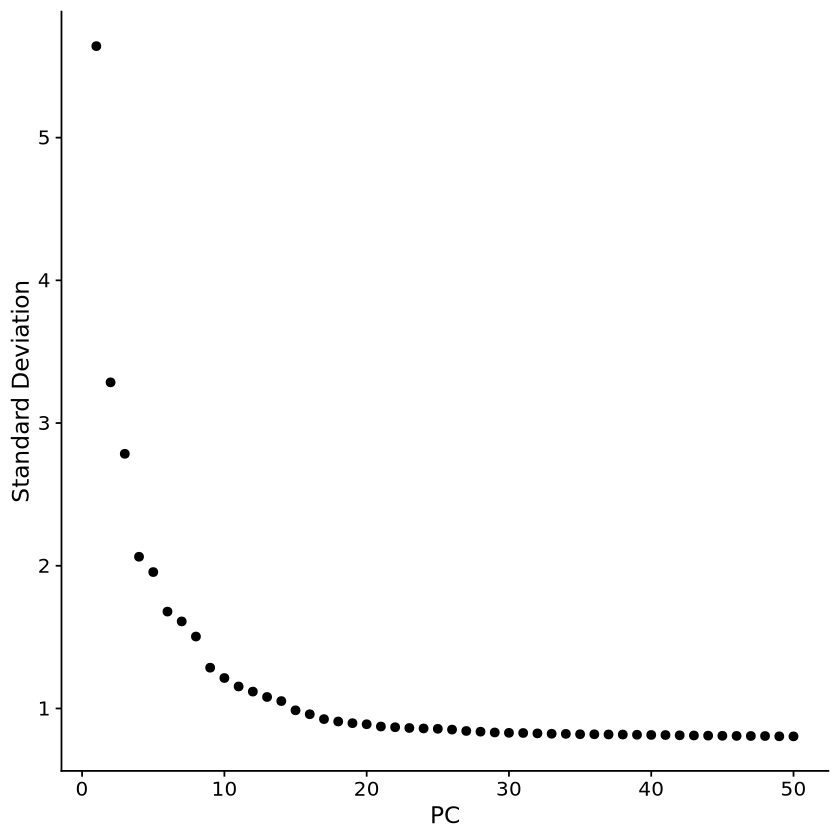

In [2]:
# ==============================================================================
# CELL 9A — RELOAD THE INTEGRATED OBJECT AND RUN PCA
# ==============================================================================
#
# The prior R session ended, so the in-memory object s disappeared.
# This cell reloads the successfully saved integrated checkpoint, validates it,
# runs PCA on the integrated assay, and saves a post-PCA checkpoint.
#
# The authors' corresponding steps were:
#
#   DefaultAssay(s) <- "integrated"
#   s <- RunPCA(s)
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
})


# ------------------------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------------------------

figure1d_output_dir <- paste0(
  "/home/amithsiri/projects/",
  "Summer-Project-2026/",
  "Summer-Project-2026/",
  "Age_trajectory/",
  "results/",
  "figure1d_python"
)


integrated_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_seurat_integrated.rds"
)


pca_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_after_PCA.rds"
)


# ------------------------------------------------------------------------------
# 2. Confirm the integrated checkpoint exists
# ------------------------------------------------------------------------------

if (!file.exists(integrated_checkpoint_path)) {
  stop(
    paste0(
      "Integrated checkpoint not found:\n",
      integrated_checkpoint_path
    )
  )
}


cat(
  "Integrated checkpoint found.\n",
  "Path: ",
  integrated_checkpoint_path,
  "\n",
  "Size: ",
  round(
    file.info(integrated_checkpoint_path)$size / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 3. Reload the integrated Seurat object
#
# Reading a compressed 4.17 GB RDS may take several minutes.
# ------------------------------------------------------------------------------

cat("\nLoading integrated Seurat object...\n")

load_start <- Sys.time()


s <- readRDS(
  integrated_checkpoint_path
)


load_minutes <- as.numeric(
  difftime(
    Sys.time(),
    load_start,
    units = "mins"
  )
)


cat(
  "Integrated object loaded in ",
  round(load_minutes, 2),
  " minutes.\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 4. Validate the reloaded object
# ------------------------------------------------------------------------------

if (!inherits(s, "Seurat")) {
  stop(
    "The checkpoint did not contain a Seurat object."
  )
}


if (!"integrated" %in% Assays(s)) {
  stop(
    "The reloaded object does not contain an integrated assay."
  )
}


if (ncol(s) != 70391) {
  stop(
    paste0(
      "Expected 70,391 cells, but found ",
      format(ncol(s), big.mark = ","),
      "."
    )
  )
}


if (nrow(s[["integrated"]]) != 2000) {
  stop(
    paste0(
      "Expected 2,000 integrated features, but found ",
      format(nrow(s[["integrated"]]), big.mark = ","),
      "."
    )
  )
}


DefaultAssay(s) <- "integrated"


cat("\nReloaded-object validation:\n")

cat(
  "  Assays: ",
  paste(Assays(s), collapse = ", "),
  "\n",
  sep = ""
)

cat(
  "  Active assay: ",
  DefaultAssay(s),
  "\n",
  sep = ""
)

cat(
  "  Integrated dimensions: ",
  format(nrow(s[["integrated"]]), big.mark = ","),
  " features × ",
  format(ncol(s), big.mark = ","),
  " cells\n",
  sep = ""
)

cat(
  "  Object size in memory: ",
  round(as.numeric(object.size(s)) / 1024^3, 3),
  " GB\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 5. Run PCA
#
# The authors called RunPCA without specifying npcs, so Seurat's default number
# of principal components is retained.
# ------------------------------------------------------------------------------

cat("\nRunning PCA on the integrated assay...\n")

set.seed(12345)

pca_start <- Sys.time()


s <- RunPCA(
  object = s,
  assay = "integrated",
  verbose = TRUE,
  seed.use = 12345
)


pca_minutes <- as.numeric(
  difftime(
    Sys.time(),
    pca_start,
    units = "mins"
  )
)


# ------------------------------------------------------------------------------
# 6. Validate the PCA result
# ------------------------------------------------------------------------------

if (!"pca" %in% Reductions(s)) {
  stop(
    "PCA reduction was not created."
  )
}


pca_embeddings <- Embeddings(
  s,
  reduction = "pca"
)


pca_cells <- nrow(
  pca_embeddings
)


pca_dimensions <- ncol(
  pca_embeddings
)


if (pca_cells != 70391) {
  stop(
    paste0(
      "Expected PCA embeddings for 70,391 cells, but found ",
      format(pca_cells, big.mark = ","),
      "."
    )
  )
}


if (pca_dimensions < 15) {
  stop(
    paste0(
      "The authors require at least 15 PCs, but only ",
      pca_dimensions,
      " were created."
    )
  )
}


cat("\nPCA validation:\n")

cat(
  "  Cells embedded: ",
  format(pca_cells, big.mark = ","),
  "\n",
  sep = ""
)

cat(
  "  PCs created: ",
  pca_dimensions,
  "\n",
  sep = ""
)

cat(
  "  First 15 PCs available: ",
  pca_dimensions >= 15,
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 7. Create and save the elbow plot
# ------------------------------------------------------------------------------

elbow_plot_path <- file.path(
  figure1d_output_dir,
  "GSE200164_PCA_elbow_plot.png"
)


elbow_plot <- ElbowPlot(
  object = s,
  ndims = min(
    50,
    pca_dimensions
  )
)


print(
  elbow_plot
)


ggsave(
  filename = elbow_plot_path,
  plot = elbow_plot,
  width = 6,
  height = 4,
  units = "in",
  dpi = 300
)


# ------------------------------------------------------------------------------
# 8. Save the PCA checkpoint
# ------------------------------------------------------------------------------

temporary_pca_path <- paste0(
  pca_checkpoint_path,
  ".tmp"
)


if (file.exists(temporary_pca_path)) {
  file.remove(
    temporary_pca_path
  )
}


cat("\nSaving post-PCA checkpoint...\n")


save_start <- Sys.time()


saveRDS(
  object = s,
  file = temporary_pca_path,
  compress = "gzip"
)


save_minutes <- as.numeric(
  difftime(
    Sys.time(),
    save_start,
    units = "mins"
  )
)


if (!file.exists(temporary_pca_path)) {
  stop(
    "The temporary PCA checkpoint was not created."
  )
}


if (file.exists(pca_checkpoint_path)) {
  file.remove(
    pca_checkpoint_path
  )
}


rename_success <- file.rename(
  temporary_pca_path,
  pca_checkpoint_path
)


if (!rename_success) {
  stop(
    paste0(
      "The PCA checkpoint was written but could not be renamed.\n",
      "Temporary file: ",
      temporary_pca_path
    )
  )
}


# ------------------------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 9 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "Integrated checkpoint reloaded: TRUE\n"
)


cat(
  "PCA reduction created: ",
  "pca" %in% Reductions(s),
  "\n",
  sep = ""
)


cat(
  "PCA dimensions: ",
  format(pca_cells, big.mark = ","),
  " cells × ",
  pca_dimensions,
  " PCs\n",
  sep = ""
)


cat(
  "First 15 PCs available: ",
  pca_dimensions >= 15,
  "\n",
  sep = ""
)


cat(
  "PCA checkpoint exists: ",
  file.exists(pca_checkpoint_path),
  "\n",
  sep = ""
)


cat(
  "PCA checkpoint size: ",
  round(
    file.info(pca_checkpoint_path)$size / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)


cat(
  "Load runtime: ",
  round(load_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "PCA runtime: ",
  round(pca_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "Save runtime: ",
  round(save_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "Elbow plot saved: ",
  file.exists(elbow_plot_path),
  "\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 9 COMPLETE\n")
cat(separator, "\n", sep = "")

PCA dimensions: 70,391 cells × 50 PCs


Elbow plot saved: TRUE

Saving post-PCA checkpoint...


[1] TRUE


CELL 9B VALIDATION REPORT
PCA reduction present: TRUE
PCA dimensions: 70,391 cells × 50 PCs
Elbow plot saved: TRUE
PCA checkpoint saved: TRUE
PCA checkpoint size: 4.196 GB
Checkpoint save runtime: 7.29 minutes
CELL 9B COMPLETE


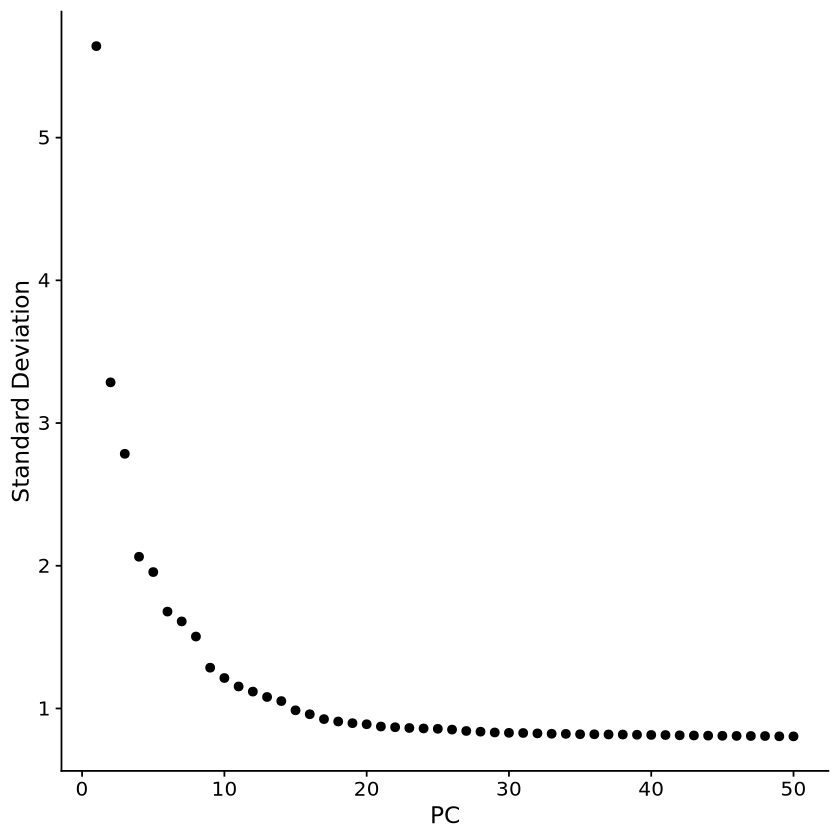

In [3]:
# ==============================================================================
# CELL 9B — SAVE THE ELBOW PLOT AND POST-PCA CHECKPOINT
# ==============================================================================
#
# PCA already completed successfully:
#   70,391 cells × 50 PCs
#
# This cell only:
#   1. loads ggplot2,
#   2. saves the elbow plot,
#   3. saves the post-PCA Seurat checkpoint.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(ggplot2)
})


# ------------------------------------------------------------------------------
# 1. Confirm PCA is still present in memory
# ------------------------------------------------------------------------------

if (!exists("s")) {
  stop(
    "The Seurat object s is no longer in memory."
  )
}


if (!"pca" %in% Reductions(s)) {
  stop(
    "The PCA reduction is missing. Do not continue."
  )
}


pca_embeddings <- Embeddings(
  s,
  reduction = "pca"
)


cat(
  "PCA dimensions: ",
  format(nrow(pca_embeddings), big.mark = ","),
  " cells × ",
  ncol(pca_embeddings),
  " PCs\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 2. Recreate and save the elbow plot
# ------------------------------------------------------------------------------

elbow_plot_path <- file.path(
  figure1d_output_dir,
  "GSE200164_PCA_elbow_plot.png"
)


elbow_plot <- ElbowPlot(
  object = s,
  ndims = min(
    50,
    ncol(pca_embeddings)
  )
)


print(elbow_plot)


ggplot2::ggsave(
  filename = elbow_plot_path,
  plot = elbow_plot,
  width = 6,
  height = 4,
  units = "in",
  dpi = 300
)


cat(
  "Elbow plot saved: ",
  file.exists(elbow_plot_path),
  "\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 3. Save the post-PCA checkpoint
# ------------------------------------------------------------------------------

pca_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_after_PCA.rds"
)


temporary_pca_path <- paste0(
  pca_checkpoint_path,
  ".tmp"
)


if (file.exists(temporary_pca_path)) {
  file.remove(
    temporary_pca_path
  )
}


cat("\nSaving post-PCA checkpoint...\n")


save_start <- Sys.time()


saveRDS(
  object = s,
  file = temporary_pca_path,
  compress = "gzip"
)


save_minutes <- as.numeric(
  difftime(
    Sys.time(),
    save_start,
    units = "mins"
  )
)


if (!file.exists(temporary_pca_path)) {
  stop(
    "The temporary PCA checkpoint was not created."
  )
}


if (file.exists(pca_checkpoint_path)) {
  file.remove(
    pca_checkpoint_path
  )
}


rename_success <- file.rename(
  temporary_pca_path,
  pca_checkpoint_path
)


if (!rename_success) {
  stop(
    paste0(
      "The PCA checkpoint was written but could not be renamed.\n",
      "Temporary file: ",
      temporary_pca_path
    )
  )
}


# ------------------------------------------------------------------------------
# 4. Final report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 9B VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "PCA reduction present: ",
  "pca" %in% Reductions(s),
  "\n",
  sep = ""
)


cat(
  "PCA dimensions: ",
  format(nrow(pca_embeddings), big.mark = ","),
  " cells × ",
  ncol(pca_embeddings),
  " PCs\n",
  sep = ""
)


cat(
  "Elbow plot saved: ",
  file.exists(elbow_plot_path),
  "\n",
  sep = ""
)


cat(
  "PCA checkpoint saved: ",
  file.exists(pca_checkpoint_path),
  "\n",
  sep = ""
)


cat(
  "PCA checkpoint size: ",
  round(
    file.info(pca_checkpoint_path)$size / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)


cat(
  "Checkpoint save runtime: ",
  round(save_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 9B COMPLETE\n")
cat(separator, "\n", sep = "")

Validated PCA object: 70,391 cells × 50 PCs

Running FindNeighbors with PCs 1–15...


Computing nearest neighbor graph

Computing SNN



FindNeighbors completed in 0.36 minutes.

Graphs present: integrated_nn, integrated_snn

Running FindClusters at resolution 0.3...
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 70391
Number of edges: 1895014

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8991
Number of communities: 10
Elapsed time: 19 seconds
FindClusters completed in 0.33 minutes.

Number of clusters: 10

Cells per cluster:

    9     8     7     6     5     4     3     2     1     0 
  940   951  1293  2023  2170  4045  5073 15721 17703 20472 

Running UMAP with PCs 1–15 and 30 neighbors...


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
22:54:37 UMAP embedding parameters a = 0.9922 b = 1.112

22:54:37 Read 70391 rows and found 15 numeric columns

22:54:37 Using Annoy for neighbor search, n_neighbors = 30

22:54:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

22:54:43 Writing NN index file to temp file /tmp/RtmpsWPIfJ/filefab342ed99b

22:54:43 Searching Annoy index using 1 thread, search_k = 3000

22:55:12 Annoy recall = 100%

22:55:13 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors =

RunUMAP completed in 1.21 minutes.

UMAP dimensions: 70,391 cells × 2 coordinates


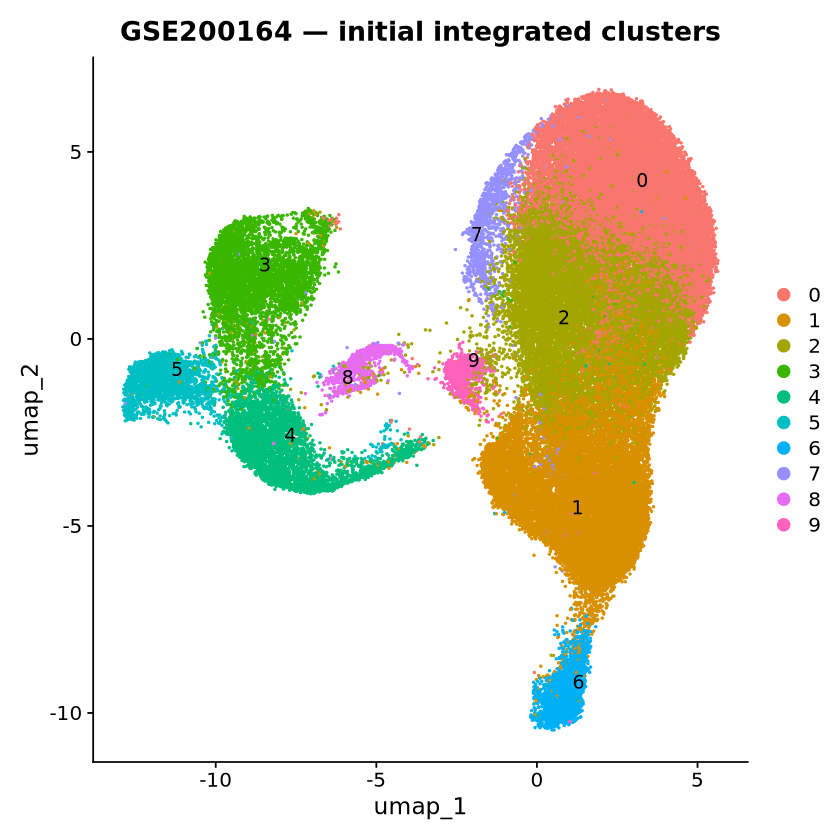

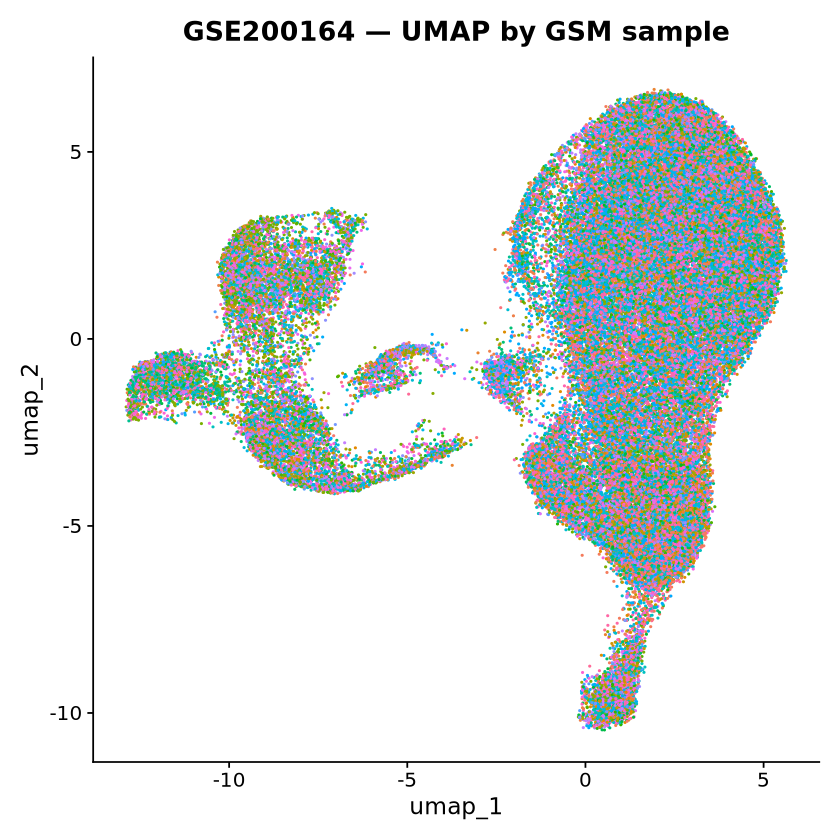


Saving post-UMAP checkpoint...


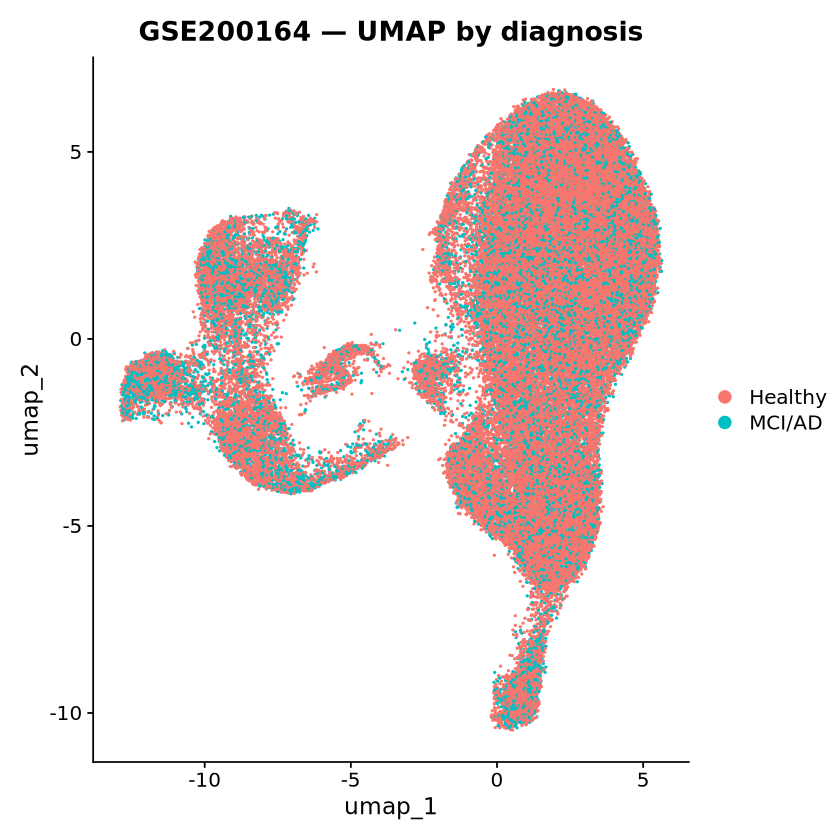

In [4]:
# ==============================================================================
# CELL 10 — BUILD NEIGHBOR GRAPH, CLUSTER CELLS, AND RUN UMAP
# ==============================================================================
#
# Authors' workflow:
#
#   s <- FindNeighbors(s, dims = 1:15)
#   s <- FindClusters(s, resolution = 0.3)
#   s <- RunUMAP(s, dims = 1:15, n.neighbors = 30)
#
# This cell:
#   1. reloads the PCA checkpoint if s is not in memory,
#   2. validates PCA,
#   3. builds the shared nearest-neighbor graph,
#   4. runs graph clustering,
#   5. runs UMAP,
#   6. saves plots and a post-UMAP checkpoint.
# ==============================================================================


suppressPackageStartupMessages({
  library(Seurat)
  library(ggplot2)
})


# ------------------------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------------------------

figure1d_output_dir <- paste0(
  "/home/amithsiri/projects/",
  "Summer-Project-2026/",
  "Summer-Project-2026/",
  "Age_trajectory/",
  "results/",
  "figure1d_python"
)


pca_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_after_PCA.rds"
)


umap_checkpoint_path <- file.path(
  figure1d_output_dir,
  "GSE200164_after_neighbors_clusters_umap.rds"
)


# ------------------------------------------------------------------------------
# 2. Reload the PCA object if necessary
# ------------------------------------------------------------------------------

if (!exists("s")) {

  if (!file.exists(pca_checkpoint_path)) {
    stop(
      paste0(
        "The Seurat object is not in memory and the PCA checkpoint is missing:\n",
        pca_checkpoint_path
      )
    )
  }

  cat("Reloading PCA checkpoint...\n")

  s <- readRDS(
    pca_checkpoint_path
  )

  cat("PCA checkpoint loaded.\n")
}


# ------------------------------------------------------------------------------
# 3. Validate the PCA object
# ------------------------------------------------------------------------------

if (!inherits(s, "Seurat")) {
  stop(
    "s is not a Seurat object."
  )
}


if (!"integrated" %in% Assays(s)) {
  stop(
    "The integrated assay is missing."
  )
}


if (!"pca" %in% Reductions(s)) {
  stop(
    "The PCA reduction is missing."
  )
}


pca_embeddings <- Embeddings(
  s,
  reduction = "pca"
)


if (ncol(pca_embeddings) < 15) {
  stop(
    paste0(
      "At least 15 PCs are required, but only ",
      ncol(pca_embeddings),
      " are available."
    )
  )
}


if (nrow(pca_embeddings) != 70391) {
  stop(
    paste0(
      "Expected PCA embeddings for 70,391 cells, but found ",
      format(nrow(pca_embeddings), big.mark = ","),
      "."
    )
  )
}


DefaultAssay(s) <- "integrated"


cat(
  "Validated PCA object: ",
  format(nrow(pca_embeddings), big.mark = ","),
  " cells × ",
  ncol(pca_embeddings),
  " PCs\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 4. Set reproducible random seed
# ------------------------------------------------------------------------------

set.seed(12345)


# ------------------------------------------------------------------------------
# 5. Build the nearest-neighbor and shared nearest-neighbor graphs
#
# This matches:
#
#   FindNeighbors(s, dims = 1:15)
# ------------------------------------------------------------------------------

cat("\nRunning FindNeighbors with PCs 1–15...\n")

neighbors_start <- Sys.time()


s <- FindNeighbors(
  object = s,
  reduction = "pca",
  dims = 1:15,
  verbose = TRUE
)


neighbors_minutes <- as.numeric(
  difftime(
    Sys.time(),
    neighbors_start,
    units = "mins"
  )
)


cat(
  "FindNeighbors completed in ",
  round(neighbors_minutes, 2),
  " minutes.\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 6. Validate graph creation
# ------------------------------------------------------------------------------

graph_names <- names(
  s@graphs
)


cat(
  "\nGraphs present: ",
  paste(graph_names, collapse = ", "),
  "\n",
  sep = ""
)


if (length(graph_names) == 0) {
  stop(
    "FindNeighbors did not create any graph objects."
  )
}


# ------------------------------------------------------------------------------
# 7. Cluster the cells
#
# The authors state Louvain clustering at resolution 0.3.
#
# algorithm = 1 explicitly requests the original Louvain implementation,
# avoiding ambiguity across Seurat versions.
# ------------------------------------------------------------------------------

cat("\nRunning FindClusters at resolution 0.3...\n")

clusters_start <- Sys.time()


s <- FindClusters(
  object = s,
  resolution = 0.3,
  algorithm = 1,
  random.seed = 12345,
  verbose = TRUE
)


clusters_minutes <- as.numeric(
  difftime(
    Sys.time(),
    clusters_start,
    units = "mins"
  )
)


cat(
  "FindClusters completed in ",
  round(clusters_minutes, 2),
  " minutes.\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 8. Validate cluster assignments
# ------------------------------------------------------------------------------

if (!"seurat_clusters" %in% colnames(s@meta.data)) {
  stop(
    "FindClusters did not create the seurat_clusters metadata column."
  )
}


cluster_counts <- sort(
  table(
    s$seurat_clusters
  )
)


n_clusters <- length(
  cluster_counts
)


cat(
  "\nNumber of clusters: ",
  n_clusters,
  "\n",
  sep = ""
)


cat("\nCells per cluster:\n")

print(
  cluster_counts
)


if (sum(cluster_counts) != 70391) {
  stop(
    "The cluster assignments do not include all 70,391 cells."
  )
}


# ------------------------------------------------------------------------------
# 9. Run UMAP
#
# This matches:
#
#   RunUMAP(s, dims = 1:15, n.neighbors = 30)
#
# The authors did not explicitly set min.dist, metric, or spread, so Seurat
# defaults are retained.
# ------------------------------------------------------------------------------

cat("\nRunning UMAP with PCs 1–15 and 30 neighbors...\n")

umap_start <- Sys.time()


s <- RunUMAP(
  object = s,
  reduction = "pca",
  dims = 1:15,
  n.neighbors = 30,
  seed.use = 12345,
  verbose = TRUE
)


umap_minutes <- as.numeric(
  difftime(
    Sys.time(),
    umap_start,
    units = "mins"
  )
)


cat(
  "RunUMAP completed in ",
  round(umap_minutes, 2),
  " minutes.\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 10. Validate UMAP
# ------------------------------------------------------------------------------

if (!"umap" %in% Reductions(s)) {
  stop(
    "The UMAP reduction was not created."
  )
}


umap_embeddings <- Embeddings(
  s,
  reduction = "umap"
)


if (nrow(umap_embeddings) != 70391) {
  stop(
    paste0(
      "Expected UMAP coordinates for 70,391 cells, but found ",
      format(nrow(umap_embeddings), big.mark = ","),
      "."
    )
  )
}


if (ncol(umap_embeddings) != 2) {
  stop(
    paste0(
      "Expected two UMAP dimensions, but found ",
      ncol(umap_embeddings),
      "."
    )
  )
}


cat(
  "\nUMAP dimensions: ",
  format(nrow(umap_embeddings), big.mark = ","),
  " cells × ",
  ncol(umap_embeddings),
  " coordinates\n",
  sep = ""
)


# ------------------------------------------------------------------------------
# 11. Plot the unsupervised numerical clusters
# ------------------------------------------------------------------------------

cluster_umap_plot <- DimPlot(
  object = s,
  reduction = "umap",
  group.by = "seurat_clusters",
  label = TRUE,
  repel = TRUE,
  pt.size = 0.2,
  shuffle = TRUE
) +
  ggtitle(
    "GSE200164 — initial integrated clusters"
  )


print(
  cluster_umap_plot
)


cluster_umap_path <- file.path(
  figure1d_output_dir,
  "GSE200164_UMAP_initial_clusters.png"
)


ggplot2::ggsave(
  filename = cluster_umap_path,
  plot = cluster_umap_plot,
  width = 10,
  height = 8,
  units = "in",
  dpi = 300
)


# ------------------------------------------------------------------------------
# 12. Plot UMAP by GSM sample
# ------------------------------------------------------------------------------

gsm_umap_plot <- DimPlot(
  object = s,
  reduction = "umap",
  group.by = "gsm",
  pt.size = 0.1,
  shuffle = TRUE
) +
  ggtitle(
    "GSE200164 — UMAP by GSM sample"
  ) +
  NoLegend()


print(
  gsm_umap_plot
)


gsm_umap_path <- file.path(
  figure1d_output_dir,
  "GSE200164_UMAP_by_GSM.png"
)


ggplot2::ggsave(
  filename = gsm_umap_path,
  plot = gsm_umap_plot,
  width = 10,
  height = 8,
  units = "in",
  dpi = 300
)


# ------------------------------------------------------------------------------
# 13. Plot UMAP by diagnosis, when available
# ------------------------------------------------------------------------------

diagnosis_column <- NULL


if ("diagnosis" %in% colnames(s@meta.data)) {

  diagnosis_column <- "diagnosis"

} else if ("Diagnosis" %in% colnames(s@meta.data)) {

  diagnosis_column <- "Diagnosis"
}


diagnosis_umap_path <- NA_character_


if (!is.null(diagnosis_column)) {

  diagnosis_umap_plot <- DimPlot(
    object = s,
    reduction = "umap",
    group.by = diagnosis_column,
    pt.size = 0.15,
    shuffle = TRUE
  ) +
    ggtitle(
      "GSE200164 — UMAP by diagnosis"
    )


  print(
    diagnosis_umap_plot
  )


  diagnosis_umap_path <- file.path(
    figure1d_output_dir,
    "GSE200164_UMAP_by_diagnosis.png"
  )


  ggplot2::ggsave(
    filename = diagnosis_umap_path,
    plot = diagnosis_umap_plot,
    width = 8,
    height = 6,
    units = "in",
    dpi = 300
  )
}


# ------------------------------------------------------------------------------
# 14. Save the post-UMAP checkpoint
# ------------------------------------------------------------------------------

temporary_umap_path <- paste0(
  umap_checkpoint_path,
  ".tmp"
)


if (file.exists(temporary_umap_path)) {
  file.remove(
    temporary_umap_path
  )
}


cat("\nSaving post-UMAP checkpoint...\n")


save_start <- Sys.time()


saveRDS(
  object = s,
  file = temporary_umap_path,
  compress = "gzip"
)


save_minutes <- as.numeric(
  difftime(
    Sys.time(),
    save_start,
    units = "mins"
  )
)


if (!file.exists(temporary_umap_path)) {
  stop(
    "The temporary post-UMAP checkpoint was not created."
  )
}


if (file.exists(umap_checkpoint_path)) {
  file.remove(
    umap_checkpoint_path
  )
}


rename_success <- file.rename(
  temporary_umap_path,
  umap_checkpoint_path
)


if (!rename_success) {
  stop(
    paste0(
      "The post-UMAP checkpoint was written but could not be renamed.\n",
      "Temporary file: ",
      temporary_umap_path
    )
  )
}


# ------------------------------------------------------------------------------
# 15. Export cluster assignments and UMAP coordinates
# ------------------------------------------------------------------------------

cluster_umap_table <- data.frame(
  cell_barcode = rownames(umap_embeddings),
  UMAP_1 = umap_embeddings[, 1],
  UMAP_2 = umap_embeddings[, 2],
  seurat_cluster = as.character(
    s$seurat_clusters[
      rownames(umap_embeddings)
    ]
  ),
  gsm = as.character(
    s$gsm[
      rownames(umap_embeddings)
    ]
  ),
  stringsAsFactors = FALSE
)


if (!is.null(diagnosis_column)) {

  cluster_umap_table$diagnosis <- as.character(
    s[[diagnosis_column]][
      rownames(umap_embeddings),
      1
    ]
  )
}


cluster_umap_csv_path <- file.path(
  figure1d_output_dir,
  "GSE200164_initial_clusters_and_umap.csv"
)


write.csv(
  cluster_umap_table,
  file = cluster_umap_csv_path,
  row.names = FALSE
)


# ------------------------------------------------------------------------------
# 16. Final report
# ------------------------------------------------------------------------------

separator <- paste(
  rep("=", 80),
  collapse = ""
)


cat("\n", separator, "\n", sep = "")
cat("CELL 10 VALIDATION REPORT\n")
cat(separator, "\n", sep = "")


cat(
  "Neighbor graphs created: ",
  length(graph_names) > 0,
  "\n",
  sep = ""
)


cat(
  "Graph names: ",
  paste(graph_names, collapse = ", "),
  "\n",
  sep = ""
)


cat(
  "Clusters created: ",
  n_clusters,
  "\n",
  sep = ""
)


cat(
  "Clustered cells: ",
  format(sum(cluster_counts), big.mark = ","),
  "\n",
  sep = ""
)


cat(
  "UMAP reduction created: ",
  "umap" %in% Reductions(s),
  "\n",
  sep = ""
)


cat(
  "UMAP dimensions: ",
  format(nrow(umap_embeddings), big.mark = ","),
  " cells × ",
  ncol(umap_embeddings),
  "\n",
  sep = ""
)


cat(
  "Cluster plot saved: ",
  file.exists(cluster_umap_path),
  "\n",
  sep = ""
)


cat(
  "GSM plot saved: ",
  file.exists(gsm_umap_path),
  "\n",
  sep = ""
)


cat(
  "Post-UMAP checkpoint saved: ",
  file.exists(umap_checkpoint_path),
  "\n",
  sep = ""
)


cat(
  "Post-UMAP checkpoint size: ",
  round(
    file.info(umap_checkpoint_path)$size / 1024^3,
    3
  ),
  " GB\n",
  sep = ""
)


cat(
  "FindNeighbors runtime: ",
  round(neighbors_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "FindClusters runtime: ",
  round(clusters_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "UMAP runtime: ",
  round(umap_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "Checkpoint save runtime: ",
  round(save_minutes, 2),
  " minutes\n",
  sep = ""
)


cat(
  "Cluster/UMAP table saved: ",
  file.exists(cluster_umap_csv_path),
  "\n",
  sep = ""
)


cat(separator, "\n", sep = "")
cat("CELL 10 COMPLETE\n")
cat(separator, "\n", sep = "")